# Proyecto final: Airbnb Bogotá
## Pregunta 1: ¿cuánto se debería cobrar por noche según las características de la propiedad?

**Datos.** Inside Airbnb, Bogotá, septiembre de 2026.
**Variable a predecir.** El precio por noche en pesos colombianos.
**Tipo de problema.** Regresión, porque el precio es una cantidad continua.

In [2]:
import warnings                                   # módulo para controlar los avisos (warnings) de Python
warnings.filterwarnings("ignore")                 # oculta los avisos para que el notebook se vea limpio

from pathlib import Path                          # Path sirve para manejar rutas de carpetas y archivos
import numpy as np                                # numpy: operaciones matemáticas y arreglos numéricos
import pandas as pd                               # pandas: manejo de tablas (DataFrames)
import matplotlib.pyplot as plt                   # matplotlib: para hacer gráficos
import seaborn as sns                             # seaborn: gráficos estadísticos más bonitos, se apoya en matplotlib

from sklearn.base import BaseEstimator, TransformerMixin   # clases base para crear mis propios transformadores
from sklearn.model_selection import train_test_split       # divide los datos en entrenamiento y prueba
from sklearn.model_selection import KFold                  # define cómo partir los datos para la validación cruzada
from sklearn.model_selection import cross_validate         # corre la validación cruzada y devuelve las métricas
from sklearn.compose import ColumnTransformer              # aplica un tratamiento distinto a cada grupo de columnas
from sklearn.compose import TransformedTargetRegressor     # entrena el modelo sobre un objetivo transformado (log) y devuelve la predicción en pesos
from sklearn.pipeline import Pipeline                      # encadena preparación de datos + modelo en un solo objeto
from sklearn.impute import SimpleImputer                   # rellena valores vacíos (nulos)
from sklearn.preprocessing import OneHotEncoder            # convierte categorías (texto) en columnas de 0 y 1
from sklearn.preprocessing import StandardScaler           # pone las variables numéricas en la misma escala
from sklearn.metrics import mean_absolute_error            # MAE: error promedio absoluto
from sklearn.metrics import mean_squared_error             # MSE: error cuadrático (de aquí sale el RMSE)
from sklearn.metrics import r2_score                       # R²: qué proporción de la variación explica el modelo

from sklearn.linear_model import LinearRegression, Ridge   # regresión lineal y su versión con penalización (Ridge)
from sklearn.neighbors import KNeighborsRegressor          # KNN: predice según los vecinos más parecidos
from sklearn.tree import DecisionTreeRegressor             # árbol de decisión
from sklearn.ensemble import RandomForestRegressor         # bosque aleatorio: muchos árboles que votan
from sklearn.ensemble import GradientBoostingRegressor     # boosting: árboles que corrigen los errores del anterior
from sklearn.svm import SVR                                # máquina de soporte vectorial para regresión
from sklearn.neural_network import MLPRegressor            # red neuronal sencilla (perceptrón multicapa)
from xgboost import XGBRegressor                           # XGBoost: boosting optimizado, muy usado en competencias

DATOS = Path("../datos")                          # ruta a la carpeta de datos (sube un nivel desde notebooks/ y entra a datos/)
pd.set_option("display.max_columns", 100)         # pandas mostrará hasta 100 columnas sin recortarlas con "..."
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")   # muestra los decimales con separador de miles y 2 decimales
sns.set_theme(style="whitegrid")                  # estilo de los gráficos: fondo claro con cuadrícula

print("Datos encontrados:", sorted(p.name for p in DATOS.glob("*.csv.gz")))   # lista los archivos .csv.gz de la carpeta datos, ordenados

TINTA, ACENTO, MORADO, GRIS = "#1B1A2F", "#E8963C", "#4C3F91", "#8A879E"   # colores del proyecto
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,          # estilo comun de todas las figuras
                     "axes.spines.right": False, "axes.grid": True,
                     "axes.axisbelow": True, "grid.color": "#E6E4EC",
                     "grid.linewidth": 0.7, "legend.frameon": False})


Datos encontrados: ['calendar.csv.gz', 'listings.csv.gz', 'reviews.csv.gz']


## Paso 1: ¿Necesitamos ML?

La tabla `listings` tiene una fila por alojamiento publicado en Airbnb Bogotá.

In [3]:
listings = pd.read_csv(                          # lee el archivo CSV comprimido y lo guarda como tabla (DataFrame)
    DATOS / "listings.csv.gz",                   # ruta del archivo: la carpeta datos + el nombre del archivo
    dtype={"price": str},                        # fuerza la columna price a texto, porque viene como "$274,830.78" y hay que limpiarla después
    low_memory=False,                            # lee el archivo completo de una vez para que pandas no adivine mal los tipos de columna
)                                                # cierra la lectura

print("Filas y columnas:", listings.shape)       # muestra cuántas filas (alojamientos) y columnas (variables) tiene la tabla

Filas y columnas: (19505, 90)


In [4]:
print(listings["price"].head())                  # muestra los primeros 5 precios tal como vienen (texto con $ y comas)
print("Precios vacíos:", listings["price"].isna().sum())   # cuenta cuántos alojamientos no tienen precio (isna marca los vacíos y sum los cuenta)

0    $274,830.78
1     $71,692.74
2    $137,358.40
3    $173,779.33
4     $67,154.71
Name: price, dtype: object
Precios vacíos: 711


### Regla a mano

Sin un modelo, un propietario miraría el precio típico de su barrio y cobraría eso. La mediana
por barrio es esa regla, y su error es el que cualquier modelo tiene que reducir para
justificar su uso.

In [5]:
def a_numero(serie):                                         # función que convierte el precio de texto a número
    sin_signo = serie.str.replace("$", "", regex=False)      # quita el signo $ del texto (regex=False para tratarlo como símbolo normal)
    sin_coma = sin_signo.str.replace(",", "", regex=False)   # quita las comas de los miles
    return sin_coma.astype(float)                            # convierte el texto limpio a número decimal

listings["price_num"] = a_numero(listings["price"])          # crea la columna price_num con el precio ya como número
datos = listings.dropna(subset=["price_num"]).copy()         # quita los 711 alojamientos sin precio (no sirven para aprender) y guarda una copia
print("Alojamientos con precio:", datos.shape[0])            # cuenta cuántas filas quedaron

Alojamientos con precio: 18794


In [6]:
train, test = train_test_split(                              # divide la tabla en dos partes: entrenamiento y prueba
    datos,                                                   # la tabla que vamos a dividir
    test_size=0.2,                                           # 20% de los datos se guarda para la prueba final
    random_state=42,                                         # semilla fija para que la división sea siempre la misma
)                                                            # cierra la división
print("Entrenamiento:", train.shape[0], "| Prueba:", test.shape[0])   # muestra cuántas filas quedaron en cada parte

Entrenamiento: 15035 | Prueba: 3759


In [ ]:
mediana_barrio = train.groupby("neighbourhood_cleansed")["price_num"].median()   # calcula el precio mediano de cada barrio, usando solo entrenamiento
mediana_global = train["price_num"].median()                 # mediana de toda la ciudad, por si en prueba aparece un barrio que no vimos
pred_regla = test["neighbourhood_cleansed"].map(mediana_barrio).fillna(mediana_global)   # a cada alojamiento de prueba le asigna la mediana de su barrio (o la de la ciudad si no existe)

mae_regla = mean_absolute_error(test["price_num"], pred_regla)               # MAE: en promedio, cuántos pesos se equivoca la regla
rmse_regla = np.sqrt(mean_squared_error(test["price_num"], pred_regla))      # RMSE: error que castiga más los errores grandes
r2_regla = r2_score(test["price_num"], pred_regla)           # R²: qué proporción de la variación del precio explica la regla

print(f"MAE:  ${mae_regla:,.0f}")                            # imprime el MAE en pesos, sin decimales
print(f"RMSE: ${rmse_regla:,.0f}")                           # imprime el RMSE en pesos
print(f"R²:   {r2_regla:.3f}")                               # imprime el R² con 3 decimales

### Conclusión: ¿necesitamos ML?

El barrio por sí solo apenas explica el precio. El error cuadrático queda muy por encima del
error absoluto, lo que indica que unos pocos precios extremos arrastran la medida, y el R²
cercano a cero confirma que la localidad no basta.

El precio depende también del tamaño y del tipo de alojamiento, de modo que un modelo que
combine varias características tiene margen frente a la regla a mano.

## Paso 2: Datos

**De dónde salen.** Inside Airbnb, https://insideairbnb.com/get-the-data/, sección Bogotá,
Distrito Capital, Colombia, compilado el 14 de septiembre de 2026.

**Licencia.** Creative Commons Attribution 4.0, que permite el uso citando la fuente.

**Cómo se descargan.** A mano desde esa página, en tres archivos comprimidos que quedan en la
carpeta `datos/`.

| Tabla | Qué es una fila |
|---|---|
| `listings` | un alojamiento publicado |
| `reviews` | un comentario que dejó un huésped |
| `calendar` | un alojamiento en un día futuro, con su disponibilidad |

**Etiqueta.** El precio por noche. Vale la pena predecirlo porque un propietario nuevo no sabe
cuánto cobrar, y errar hacia arriba le cuesta reservas mientras que errar hacia abajo le cuesta
ingresos.

**Complejidad.** Los datos son crudos y están en tres tablas, de modo que la tabla principal
con una fila por alojamiento hay que construirla.

In [7]:
calendar_cols = pd.read_csv(DATOS / "calendar.csv.gz", nrows=0).columns   # lee solo el encabezado (0 filas) para saber qué columnas tiene calendar sin cargarla toda
reviews_cols = pd.read_csv(DATOS / "reviews.csv.gz", nrows=0).columns     # lo mismo para reviews
print("calendar:", list(calendar_cols))              # imprime los nombres de las columnas de calendar
print("reviews:", list(reviews_cols))                # imprime los nombres de las columnas de reviews

calendar: ['listing_id', 'date', 'available', 'minimum_nights', 'maximum_nights']
reviews: ['listing_id', 'id', 'date', 'reviewer_id', 'reviewer_name', 'comments']


In [8]:
calendar = pd.read_csv(                              # carga la tabla calendar (7 millones de filas, por eso solo las columnas necesarias)
    DATOS / "calendar.csv.gz",                       # ruta del archivo
    usecols=["listing_id", "date", "available"],     # solo trae: id del alojamiento, fecha y si está disponible (así gasta menos memoria)
)                                                    # cierra la lectura
reviews = pd.read_csv(                               # carga la tabla reviews
    DATOS / "reviews.csv.gz",                        # ruta del archivo
    usecols=["listing_id", "date"],                  # solo trae: id del alojamiento y fecha del comentario (el texto lo usa la parte de sentimiento)
)                                                    # cierra la lectura

print(f"listings: {listings.shape[0]:,} filas x {listings.shape[1]} columnas")           # tamaño de listings
print(f"calendar: {len(calendar):,} filas x {len(calendar_cols)} columnas (en el archivo)")   # filas cargadas y columnas totales del archivo
print(f"reviews:  {len(reviews):,} filas x {len(reviews_cols)} columnas (en el archivo)")     # lo mismo para reviews

listings: 19,505 filas x 91 columnas
calendar: 7,119,325 filas x 5 columnas (en el archivo)
reviews:  568,675 filas x 6 columnas (en el archivo)


### Resumir calendar y reviews a una fila por alojamiento

La tabla de anuncios tiene una fila por alojamiento, mientras que el calendario tiene una por
alojamiento y día y los comentarios una por comentario. Unirlas exige resumirlas primero.

`pct_ocupado_90d` recoge, de los noventa días siguientes del calendario, la proporción que
aparece como no disponible. `reviews_ult_12m` cuenta los comentarios del último año. Las dos se
calculan desde una fecha de corte, que es el día en que se tomaron los datos.

In [9]:
calendar["date"] = pd.to_datetime(calendar["date"])           # convierte la fecha de texto a fecha real, para poder comparar y restar
reviews["date"] = pd.to_datetime(reviews["date"])             # lo mismo para las fechas de los comentarios
fecha_corte = calendar["date"].min() - pd.Timedelta(days=1)   # el "hoy" de los datos: un día antes de que empiece el calendario

print("Fecha de corte:", fecha_corte.date())                  # muestra la fecha de corte
print("Calendar va de", calendar["date"].min().date(), "a", calendar["date"].max().date())   # primer y último día del calendario
print("Reviews van de", reviews["date"].min().date(), "a", reviews["date"].max().date())     # primer y último día con comentarios

Fecha de corte: 2026-09-15
Calendar va de 2026-09-16 a 2027-09-15
Reviews van de 2010-10-06 a 2026-09-16


In [10]:
primeros_90 = calendar[calendar["date"] <= fecha_corte + pd.Timedelta(days=90)]   # se queda solo con los primeros 90 días del calendario
esta_ocupado = primeros_90["available"] == "f"                # True si el día NO está disponible (en la tabla, "f" significa false)
pct_ocupado_90d = esta_ocupado.groupby(primeros_90["listing_id"]).mean()   # por alojamiento, el promedio de los True = proporción de días ocupados
pct_ocupado_90d.name = "pct_ocupado_90d"                      # le pone nombre a la columna resultante

en_ultimo_anio = (reviews["date"] > fecha_corte - pd.Timedelta(days=365)) & (reviews["date"] <= fecha_corte)   # True si el comentario cae en los 365 días antes del corte
reviews_ult_12m = reviews[en_ultimo_anio].groupby("listing_id").size()      # cuenta los comentarios del último año por alojamiento
reviews_ult_12m.name = "reviews_ult_12m"                      # le pone nombre a la columna resultante

print("Alojamientos con calendario:", len(pct_ocupado_90d))   # cuántos alojamientos aparecen en calendar
print("Alojamientos con comentarios en el último año:", len(reviews_ult_12m))   # cuántos recibieron al menos un comentario en el último año
print(pct_ocupado_90d.describe())                             # resumen estadístico del porcentaje ocupado (mínimo, promedio, máximo...)
print(reviews_ult_12m.describe())                             # resumen estadístico de los comentarios del último año

Alojamientos con calendario: 19505
Alojamientos con comentarios en el último año: 12674
count   19,505.00
mean         0.22
std          0.30
min          0.00
25%          0.02
50%          0.10
75%          0.29
max          1.00
Name: pct_ocupado_90d, dtype: float64
count   12,674.00
mean        15.17
std         23.09
min          1.00
25%          3.00
50%          8.00
75%         20.00
max        781.00
Name: reviews_ult_12m, dtype: float64


### Tabla principal

Las dos variables resumidas se unen a la tabla de anuncios por el identificador del
alojamiento. Los que no recibieron comentarios en el último año quedan en cero. De la fecha del
último comentario sale `dias_desde_ultimo_review`, que mide cuántos días pasaron hasta la fecha
de corte.

La tabla cambió de forma, de modo que la división entre entrenamiento y prueba se rehace con la
misma semilla.

In [11]:
datos = listings.merge(pct_ocupado_90d, left_on="id", right_index=True, how="left")      # pega el % ocupado a cada alojamiento, cruzando el id de listings con el listing_id de calendar
datos = datos.merge(reviews_ult_12m, left_on="id", right_index=True, how="left")         # pega los comentarios del último año, igual
datos["reviews_ult_12m"] = datos["reviews_ult_12m"].fillna(0)                            # los que no aparecen no tuvieron comentarios, así que valen 0
datos["dias_desde_ultimo_review"] = (fecha_corte - pd.to_datetime(datos["last_review"])).dt.days   # días entre el último comentario y la fecha de corte
datos["dias_desde_ultimo_review"] = datos["dias_desde_ultimo_review"].clip(lower=0)      # si salió negativo (comentario del día siguiente al corte) lo deja en 0
datos = datos.dropna(subset=["price_num"]).copy()                                        # quita los alojamientos sin precio, igual que en el Paso 1

print("Filas y columnas:", datos.shape)                                                  # tamaño de la tabla principal
print("¿Cada alojamiento aparece una sola vez?", datos["id"].is_unique)                  # comprueba que el cruce no duplicó filas
datos[["id", "neighbourhood_cleansed", "price_num", "pct_ocupado_90d", "reviews_ult_12m", "dias_desde_ultimo_review"]].head()   # muestra las primeras 5 filas con las columnas nuevas

Filas y columnas: (18794, 94)
¿Cada alojamiento aparece una sola vez? True


,id,neighbourhood_cleansed,price_num,pct_ocupado_90d,reviews_ult_12m,dias_desde_ultimo_review
0,27841,Chapinero,"274,830.78",1.00,0.00,366.00
1,3043690,Chapinero,"71,692.74",0.00,0.00,"3,979.00"
2,3218908,Chapinero,"137,358.40",1.00,1.00,293.00
3,3247862,Chapinero,"173,779.33",1.00,0.00,"1,178.00"
4,3263631,Chapinero,"67,154.71",0.66,2.00,32.00


In [12]:
# Donde estan los alojamientos y a que precio
con_precio = datos[datos["price_num"].notna()]                             # alojamientos con precio conocido

fig, ax = plt.subplots(figsize=(6.5, 6.5))                                 # figura cuadrada, porque es un mapa
puntos = ax.scatter(con_precio["longitude"], con_precio["latitude"],       # cada punto es un alojamiento
                    c=np.log1p(con_precio["price_num"]), cmap="YlOrBr",    # el color indica el precio
                    s=5, alpha=0.5, edgecolors="none")
ax.set_title("Ubicación de los alojamientos y su precio")                  # título
ax.set_xlabel("longitud"); ax.set_ylabel("latitud")                        # etiquetas de los ejes
barra = fig.colorbar(puntos, ax=ax, shrink=0.78)                           # barra de color
barra.set_label("log(1 + precio por noche)")                               # qué significa el color
ax.grid(alpha=0.25)                                                        # cuadrícula tenue
plt.tight_layout()                                                         # acomoda la figura
plt.show()                                                                 # la muestra

<Figure size 715x715 with 2 Axes>

In [13]:
train, test = train_test_split(datos, test_size=0.2, random_state=42)       # repite la división 80/20 con la misma semilla de antes
print("Entrenamiento:", train.shape[0], "| Prueba:", test.shape[0])        # muestra el tamaño de cada parte

mediana_barrio = train.groupby("neighbourhood_cleansed")["price_num"].median()   # vuelve a calcular la mediana de precio por barrio (solo entrenamiento)
mediana_global = train["price_num"].median()                                # mediana de toda la ciudad, por si aparece un barrio nuevo
pred_regla = test["neighbourhood_cleansed"].map(mediana_barrio).fillna(mediana_global)   # asigna a cada alojamiento de prueba la mediana de su barrio
print(f"MAE de la regla a mano: ${mean_absolute_error(test['price_num'], pred_regla):,.0f}")   # tiene que dar lo mismo que en el Paso 1

Entrenamiento: 15035 | Prueba: 3759
MAE de la regla a mano: $118,248


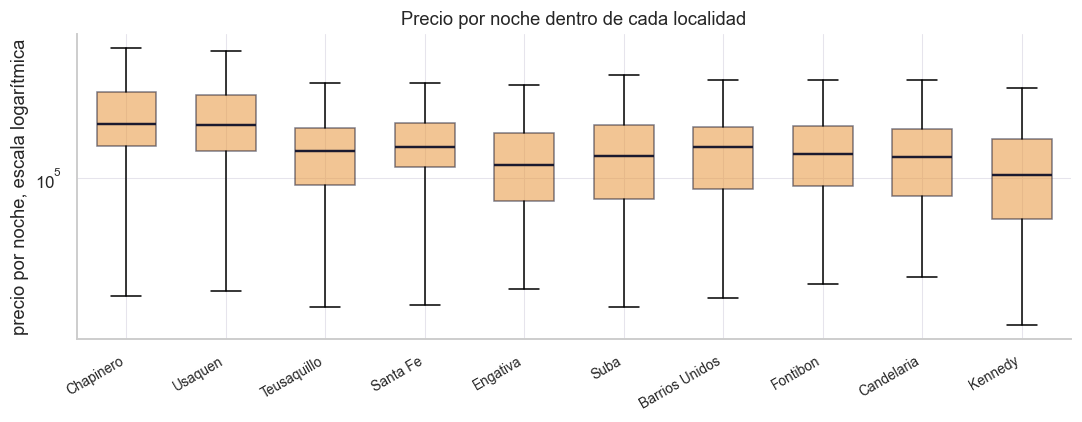

In [14]:
# Dispersion del precio dentro de cada localidad: por que el barrio no basta
top_barrios = train["neighbourhood_cleansed"].value_counts().head(10).index          # las 10 localidades con más anuncios
precios_barrio = [train.loc[train["neighbourhood_cleansed"] == b, "price_num"] for b in top_barrios]   # precios de cada una

fig, ax = plt.subplots(figsize=(10, 4))                                    # una sola figura
caja = ax.boxplot(precios_barrio, showfliers=False, patch_artist=True, widths=0.6)   # una caja por localidad, sin puntos extremos
for pieza in caja["boxes"]:                                                # pinta el cuerpo de cada caja
    pieza.set_facecolor(ACENTO); pieza.set_alpha(0.55); pieza.set_edgecolor(TINTA)
for pieza in caja["medians"]:                                              # resalta la mediana
    pieza.set_color(TINTA); pieza.set_linewidth(1.6)
ax.set_xticks(range(1, len(top_barrios) + 1))                              # una marca por localidad
ax.set_xticklabels(top_barrios, rotation=30, ha="right", fontsize=9)       # con su nombre
ax.set_yscale("log")                                                       # escala logarítmica, porque el precio es muy asimétrico
ax.set_title("Precio por noche dentro de cada localidad")                  # título
ax.set_ylabel("precio por noche, escala logarítmica")                      # etiqueta del eje vertical
plt.tight_layout()                                                         # acomoda la figura
plt.show()                                                                 # la muestra

## Paso 3: Limpieza

La revisión cubre duplicados, formatos, valores extremos, faltantes y fugas. Todas las
decisiones se toman mirando únicamente el conjunto de entrenamiento, para que la partición de
prueba conserve su papel de medida final.

El orden empieza por los precios extremos, porque el error cuadrático de la regla a mano quedó
muy por encima del error absoluto y esa diferencia apunta a precios exagerados.

In [15]:
print("Filas completamente duplicadas:", datos.duplicated().sum())          # cuenta filas idénticas en todas las columnas
print("Ids repetidos:", datos["id"].duplicated().sum())                      # cuenta alojamientos que aparecen más de una vez
print()                                                                      # línea en blanco para separar
print(train["price_num"].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99, 0.999]))   # resumen del precio con percentiles clave (1%, 5%, mediana, 95%, 99%, 99,9%)

Filas completamente duplicadas: 0
Ids repetidos: 0

count        15,035.00
mean        309,066.74
std       4,297,425.98
min          15,402.26
1%           34,389.75
5%           54,046.98
50%         160,993.92
95%         496,767.00
99%       1,275,922.67
99.9%     9,025,000.00
max     258,514,678.00
Name: price_num, dtype: float64


In [16]:
columnas_ver = ["price_num", "property_type", "room_type", "accommodates", "neighbourhood_cleansed"]   # columnas que quiero mirar de cada alojamiento
print("Los 10 más caros:")                                                   # título
display(train.nlargest(10, "price_num")[columnas_ver])                       # los 10 alojamientos con mayor precio
print("Los 5 más baratos:")                                                  # título
display(train.nsmallest(5, "price_num")[columnas_ver])                       # los 5 alojamientos con menor precio

Los 10 más caros:


,price_num,property_type,room_type,accommodates,neighbourhood_cleansed
4199,"258,514,678.00",Entire serviced apartment,Entire home/apt,2,Usaquen
18499,"232,260,501.00",Room in hotel,Private room,2,Teusaquillo
6696,"224,768,226.24",Private room in casa particular,Private room,1,Barrios Unidos
6577,"217,800,411.23",Private room in home,Private room,1,Barrios Unidos
1572,"160,000,000.00",Private room in home,Private room,2,Candelaria
3657,"150,025,000.00",Entire serviced apartment,Entire home/apt,3,Santa Fe
8203,"95,000,000.00",Entire rental unit,Entire home/apt,4,Teusaquillo
16361,"16,800,000.00",Entire rental unit,Entire home/apt,2,Chapinero
5493,"10,000,000.00",Private room in home,Private room,2,Puente Aranda
7357,"9,424,657.00",Entire rental unit,Entire home/apt,6,Fontibon


Los 5 más baratos:


,price_num,property_type,room_type,accommodates,neighbourhood_cleansed
1264,"15,402.26",Private room in condo,Private room,2,Bosa
1258,"15,896.45",Private room in home,Private room,2,Kennedy
2301,"18,794.63",Private room in home,Private room,4,Rafael Uribe Uribe
2078,"19,922.64",Private room in rental unit,Private room,1,Suba
4021,"20,025.18",Private room in casa particular,Private room,1,Teusaquillo


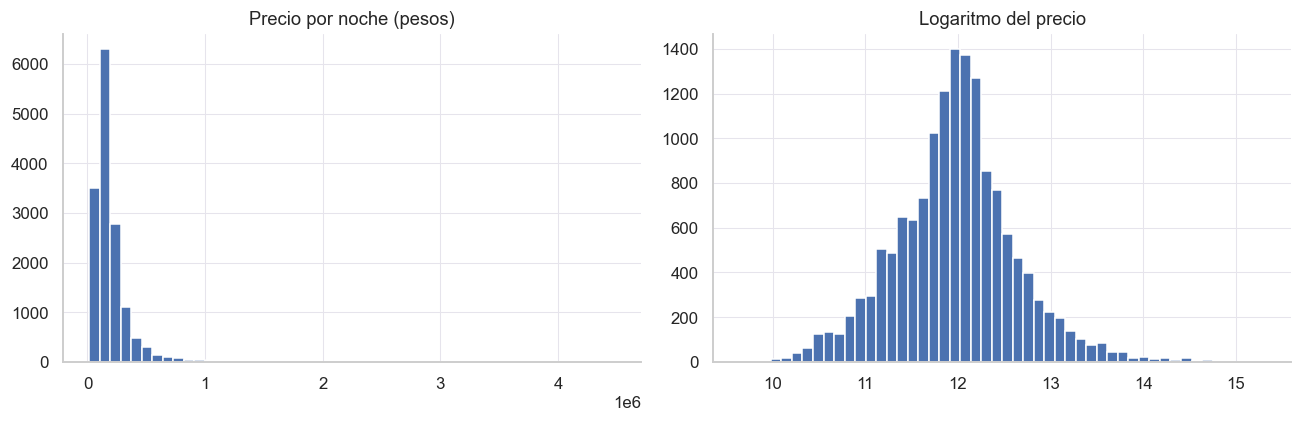

In [49]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))                              # crea una figura con dos gráficos lado a lado
ejes[0].hist(train["price_num"], bins=50)                                    # histograma del precio original, en 50 barras
ejes[0].set_title("Precio por noche (pesos)")                                # título del primer gráfico
ejes[1].hist(np.log1p(train["price_num"]), bins=50)                          # histograma del logaritmo del precio (log1p = log(1 + precio))
ejes[1].set_title("Logaritmo del precio")                                    # título del segundo gráfico
plt.tight_layout()                                                           # acomoda los gráficos para que no se pisen
plt.show()                                                                   # muestra la figura

### Valores extremos: el criterio por huésped

Hay precios imposibles, como decenas de millones por noche para dos personas, que son errores
de digitación. El criterio de Tukey sitúa el corte en el tercer cuartil más tres veces el rango
intercuartílico.

Aplicado sobre el precio total, ese criterio marca viviendas de dieciséis huéspedes cuyo precio
es alto por tamaño y no por error. El criterio se aplica entonces sobre el **precio por
huésped**, que compara alojamientos de tamaños distintos. El tope se calcula solo con
entrenamiento y se aplica a las dos particiones, porque corrige errores en la etiqueta.

In [18]:
def por_huesped(df):                                                       # función que calcula el precio por huésped de una tabla
    return df["price_num"] / df["accommodates"].clip(lower=1)              # precio dividido entre huéspedes (mínimo 1 para no dividir por cero)

columnas_ver = ["price_num", "property_type", "room_type", "accommodates", "neighbourhood_cleansed"]   # columnas que se muestran de cada alojamiento

log_pp = np.log1p(por_huesped(train))                                      # logaritmo del precio por huésped en entrenamiento
q1, q3 = log_pp.quantile([0.25, 0.75])                                     # primer y tercer cuartil
iqr = q3 - q1                                                              # rango intercuartílico
tope_pp = np.expm1(q3 + 3 * iqr)                                           # tope de Tukey (Q3 + 3 × IQR) devuelto a pesos
print(f"Tope de Tukey por huésped: ${tope_pp:,.0f}")                       # imprime el tope

extremo_train = por_huesped(train) > tope_pp                               # marca los alojamientos de entrenamiento que superan el tope
extremo_test = por_huesped(test) > tope_pp                                 # marca los de prueba que lo superan
print("Extremos en entrenamiento:", extremo_train.sum(), "| en prueba:", extremo_test.sum())   # cuántos son en cada parte

display(train[extremo_train].assign(por_huesped=por_huesped(train[extremo_train]))   # tabla de los extremos, con el precio por huésped agregado
        .sort_values("por_huesped")[columnas_ver + ["por_huesped"]].head(15))        # ordenada de menor a mayor, solo los 15 primeros


Tope de Tukey por huésped: $665,251
Extremos en entrenamiento: 71 | en prueba: 23


,price_num,property_type,room_type,accommodates,neighbourhood_cleansed,por_huesped
14624,"1,443,979.00",Entire loft,Entire home/apt,2,Chapinero,"721,989.50"
6459,"1,500,000.00",Private room in guesthouse,Private room,2,Engativa,"750,000.00"
1717,"763,262.13",Private room in rental unit,Private room,1,Suba,"763,262.13"
4970,"2,290,118.00",Entire serviced apartment,Entire home/apt,3,Chapinero,"763,372.67"
16346,"3,840,000.00",Entire rental unit,Entire home/apt,5,Teusaquillo,"768,000.00"
148,"786,501.49",Private room in home,Private room,1,Teusaquillo,"786,501.49"
8541,"1,580,000.00",Entire rental unit,Entire home/apt,2,Chapinero,"790,000.00"
4888,"2,375,000.00",Entire serviced apartment,Entire home/apt,3,Chapinero,"791,666.67"
8240,"2,375,000.00",Entire rental unit,Entire home/apt,3,Chapinero,"791,666.67"
18926,"1,599,000.00",Entire rental unit,Entire home/apt,2,Teusaquillo,"799,500.00"


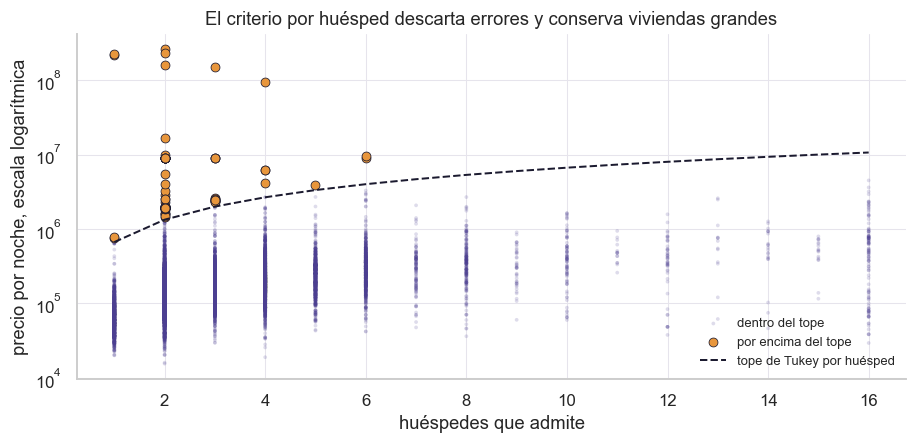

In [19]:
# El corte por huesped, visto sobre el precio y la capacidad
fig, ax = plt.subplots(figsize=(8.5, 4.2))                                 # una sola figura
dentro = train[~extremo_train]                                             # alojamientos que quedan dentro del tope
fuera = train[extremo_train]                                               # los que lo superan
ax.scatter(dentro["accommodates"], dentro["price_num"], s=6, alpha=0.18,   # los conservados
           color=MORADO, edgecolors="none", label="dentro del tope")
ax.scatter(fuera["accommodates"], fuera["price_num"], s=34, color=ACENTO,  # los descartados
           edgecolors=TINTA, linewidth=0.5, label="por encima del tope")
capacidad = np.arange(1, int(train["accommodates"].max()) + 1)             # recorrido de capacidades
ax.plot(capacidad, tope_pp * capacidad, color=TINTA, linewidth=1.3,        # el tope es una recta: tope por huésped × capacidad
        linestyle="--", label="tope de Tukey por huésped")
ax.set_yscale("log")                                                       # escala logarítmica en el precio
ax.set_title("El criterio por huésped descarta errores y conserva viviendas grandes")
ax.set_xlabel("huéspedes que admite"); ax.set_ylabel("precio por noche, escala logarítmica")
ax.legend(loc="lower right", fontsize=8.5)                                 # leyenda, porque hay tres series
plt.tight_layout()                                                         # acomoda la figura
plt.show()                                                                 # la muestra

### Aplicar el corte

Los alojamientos cuyo precio por huésped supera el tope salen de las dos particiones. Son
errores en la etiqueta, y medir el modelo contra precios imposibles no informa nada. La regla a
mano se recalcula después del corte para comparar el error antes y después.

In [20]:
def regla_a_mano(entreno, prueba):                                         # función: predice con la mediana de precio del barrio
    mediana_barrio = entreno.groupby("neighbourhood_cleansed")["price_num"].median()   # mediana de precio por barrio, calculada solo con entrenamiento
    mediana_global = entreno["price_num"].median()                         # mediana de toda la ciudad, por si aparece un barrio nuevo
    return prueba["neighbourhood_cleansed"].map(mediana_barrio).fillna(mediana_global)   # le asigna a cada alojamiento de prueba la mediana de su barrio

def metricas(y_real, y_pred):                                              # función: calcula las 4 métricas del proyecto
    return {                                                               # devuelve un diccionario con las métricas
        "MAE": mean_absolute_error(y_real, y_pred),                        # error promedio en pesos
        "RMSE": np.sqrt(mean_squared_error(y_real, y_pred)),               # error que castiga más los fallos grandes
        "R2": r2_score(y_real, y_pred),                                    # proporción de la variación que se explica
        "RMSLE": np.sqrt(mean_squared_error(np.log1p(y_real), np.log1p(y_pred))),   # error en escala logarítmica (error relativo)
    }                                                                      # cierra el diccionario

antes = metricas(test["price_num"], regla_a_mano(train, test))             # métricas de la regla a mano ANTES de limpiar

train = train[por_huesped(train) <= tope_pp].copy()                        # se queda en entrenamiento solo con los que NO superan el tope
test = test[por_huesped(test) <= tope_pp].copy()                           # lo mismo en prueba
print("Entrenamiento:", train.shape[0], "| Prueba:", test.shape[0])        # tamaños después de limpiar

despues = metricas(test["price_num"], regla_a_mano(train, test))           # métricas de la regla a mano DESPUÉS de limpiar
tabla = pd.DataFrame({"Antes de limpiar": antes, "Después de limpiar": despues})   # junta ambos resultados en una tabla

Entrenamiento: 14964 | Prueba: 3736


In [21]:
display(tabla.map(lambda x: f"{x:,.3f}"))     # muestra la tabla de antes y después; map aplica a cada número un formato con miles y 3 decimales

,Antes de limpiar,Después de limpiar
MAE,"118,247.909","92,943.425"
RMSE,"462,096.509","202,498.887"
R2,-0.009,0.005
RMSLE,0.663,0.621


### Conclusión: precios extremos

El corte sobre el precio por huésped conserva las viviendas grandes legítimas que el corte
sobre el precio total eliminaba, y descarta una fracción pequeña de la muestra.

Después de limpiar, el error de la regla a mano baja y la distancia entre el error cuadrático y
el absoluto se reduce, lo que confirma que los precios extremos eran los que inflaban el
primero. El R² sigue cerca de cero, de modo que el barrio por sí solo continúa sin explicar el
precio.

### Faltantes

La revisión cuenta los vacíos de cada columna candidata. Para las que tienen faltantes, la
estrategia de relleno se decide comparando el error de varias opciones, en lugar de escoger la
media sin justificación.

In [22]:
columnas_candidatas = [                                                    # lista de las columnas que pensamos usar para predecir
    "property_type", "room_type", "neighbourhood_cleansed",                # tipo de propiedad, tipo de habitación y barrio
    "latitude", "longitude",                                               # ubicación exacta
    "accommodates", "bedrooms", "beds", "bathrooms", "bathrooms_text",     # capacidad, habitaciones, camas y baños
    "amenities", "minimum_nights", "host_listings_count", "host_is_superhost",   # comodidades, noches mínimas, cuántos alojamientos tiene el dueño, superhost
    "review_scores_rating", "availability_90",                             # calificación y disponibilidad a 90 días
    "pct_ocupado_90d", "reviews_ult_12m", "dias_desde_ultimo_review",      # las tres variables que armamos desde calendar y reviews
]                                                                          # cierra la lista

presentes = [c for c in columnas_candidatas if c in train.columns]         # las candidatas que sí existen en la tabla
ausentes = [c for c in columnas_candidatas if c not in train.columns]      # las que no existen (por si algún nombre está distinto)
print("No existen en la tabla:", ausentes)                                 # muestra las que faltan, debería salir vacío

resumen = pd.DataFrame({                                                   # arma una tabla resumen
    "tipo": train[presentes].dtypes.astype(str),                           # tipo de dato de cada columna
    "faltantes": train[presentes].isna().sum(),                            # cuántos valores vacíos tiene cada una
    "porcentaje": (train[presentes].isna().mean() * 100).round(1),         # el mismo dato en porcentaje
}).sort_values("faltantes", ascending=False)                               # ordena de la que más faltantes tiene a la que menos
display(resumen)                                                           # muestra la tabla

No existen en la tabla: []


,tipo,faltantes,porcentaje
bathrooms,float64,14964,100.00
review_scores_rating,float64,3010,20.10
dias_desde_ultimo_review,float64,3010,20.10
beds,float64,167,1.10
bathrooms_text,object,25,0.20
minimum_nights,float64,6,0.00
bedrooms,float64,3,0.00
neighbourhood_cleansed,object,0,0.00
room_type,object,0,0.00
property_type,object,0,0.00


### Cómo rellenar los faltantes

El procedimiento compara cuatro opciones, que son la media, la mediana global, la mediana por
grupo y una regresión con bosque aleatorio. Toma los valores conocidos, esconde el veinte por
ciento, los reconstruye con cada método y mide el error absoluto medio contra el valor
verdadero. Gana el de menor error.

La comparación se hace en `beds`, `bedrooms` y `review_scores_rating`. En `minimum_nights` los
faltantes son tan pocos que se rellenan con la mediana.

In [23]:
def comparar_imputacion(columna, grupo):                                   # función: compara 4 formas de rellenar una columna; grupo es la columna para la mediana por grupo
    conocidos = train[train[columna].notna()].copy()                       # se queda solo con las filas donde el valor sí existe
    X = pd.concat([                                                        # arma las variables con las que la regresión intentará adivinar
        conocidos[["accommodates", "latitude", "longitude"]],              # capacidad y ubicación
        pd.get_dummies(conocidos["room_type"]).astype(float),              # tipo de habitación convertido en columnas de 0 y 1
    ], axis=1)                                                             # las une lado a lado
    y = conocidos[columna]                                                 # el valor real que queremos adivinar
    X_fit, X_ev, y_fit, y_ev = train_test_split(X, y, test_size=0.2, random_state=42)   # esconde 20% (evaluación) y deja 80% (para aprender)

    err_media = mean_absolute_error(y_ev, np.full(len(y_ev), y_fit.mean()))            # método 1: adivinar siempre la media
    err_mediana = mean_absolute_error(y_ev, np.full(len(y_ev), y_fit.median()))        # método 2: adivinar siempre la mediana
    med_grupo = y_fit.groupby(conocidos.loc[y_fit.index, grupo]).median()              # método 3: mediana de cada grupo (calculada con el 80%)
    pred_grupo = conocidos.loc[y_ev.index, grupo].map(med_grupo).fillna(y_fit.median())   # a cada fila escondida le asigna la mediana de su grupo
    err_grupo = mean_absolute_error(y_ev, pred_grupo)                      # error del método 3
    bosque = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)       # método 4: un bosque aleatorio (100 árboles, semilla fija)
    bosque.fit(X_fit, y_fit)                                               # el bosque aprende con el 80%
    err_reg = mean_absolute_error(y_ev, bosque.predict(X_ev))              # error del método 4 sobre el 20% escondido

    return {                                                               # devuelve los 4 errores en un diccionario
        "Media": err_media, "Mediana global": err_mediana,                 # errores de los métodos 1 y 2
        "Mediana por grupo": err_grupo, "Regresión (bosque)": err_reg,     # errores de los métodos 3 y 4
    }                                                                      # cierra el diccionario

resultados = pd.DataFrame({                                                # tabla con una fila por columna a rellenar
    "beds (grupo: accommodates)": comparar_imputacion("beds", "accommodates"),             # camas, agrupando por capacidad
    "bedrooms (grupo: accommodates)": comparar_imputacion("bedrooms", "accommodates"),     # habitaciones, agrupando por capacidad
    "review_scores_rating (grupo: room_type)": comparar_imputacion("review_scores_rating", "room_type"),   # calificación, agrupando por tipo de habitación
}).T                                                                       # .T gira la tabla: columnas pasan a ser filas
display(resultados.map(lambda x: f"{x:,.3f}"))                             # muestra los errores con 3 decimales

,Media,Mediana global,Mediana por grupo,Regresión (bosque)
beds (grupo: accommodates),0.999,0.972,0.411,0.530
bedrooms (grupo: accommodates),0.694,0.469,0.320,0.371
review_scores_rating (grupo: room_type),0.274,0.239,0.239,0.285


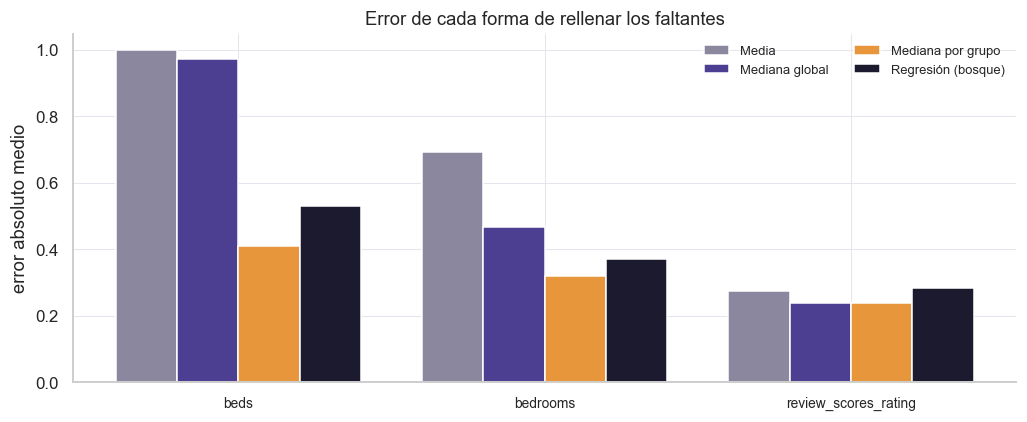

In [24]:
# Error de cada forma de rellenar los faltantes
fig, ax = plt.subplots(figsize=(9.5, 4))                                   # una sola figura
posicion = np.arange(len(resultados))                                      # una posición por columna a rellenar
ancho = 0.2                                                               # ancho de cada barra
paleta = [GRIS, MORADO, ACENTO, TINTA]                                     # un color por método
for i, metodo in enumerate(resultados.columns):                            # recorre los cuatro métodos
    ax.bar(posicion + (i - 1.5) * ancho, resultados[metodo], width=ancho,  # una barra por método y columna
           label=metodo, color=paleta[i % len(paleta)])
ax.set_xticks(posicion)                                                    # una marca por columna
ax.set_xticklabels([t.split(" (")[0] for t in resultados.index], fontsize=9)   # con el nombre de la columna
ax.set_ylabel("error absoluto medio")                                      # etiqueta del eje vertical
ax.set_title("Error de cada forma de rellenar los faltantes")              # título
ax.legend(fontsize=8.5, ncol=2)                                            # leyenda de los cuatro métodos
plt.tight_layout()                                                         # acomoda la figura
plt.show()                                                                 # la muestra

### Conclusión: faltantes

`bathrooms` llega vacía por completo, de modo que se descarta y el número de baños se extrae de
`bathrooms_text`.

En `beds` y `bedrooms` gana la mediana por grupo de capacidad, con un margen amplio sobre la
media. El mecanismo es directo, porque el número de camas y de habitaciones queda determinado
casi por completo por cuántos huéspedes admite el alojamiento, mientras que la media de la
ciudad ignora el tamaño. La regresión con bosque aleatorio quedó por detrás y es más compleja.

En `review_scores_rating` gana la mediana global, que empata con la mediana por tipo de
habitación y es más simple.

`review_scores_rating` y `dias_desde_ultimo_review` faltan en los mismos alojamientos, que son
los que nunca recibieron un comentario. Ahí el dato no existe, de modo que además del relleno
se crea la columna `sin_reviews`, que marca esos casos.

El relleno queda dentro del preprocesamiento, con las medianas aprendidas solo en
entrenamiento.

### Fugas

Una fuga es una columna que solo se conoce después de fijar el precio, o que se calcula con él.
La revisión comprueba que ninguna de las columnas candidatas lo sea.

`estimated_revenue_l365d`, el ingreso estimado del año, queda bajo sospecha porque debería ser
el precio multiplicado por las noches ocupadas, y en ese caso ya contendría la respuesta.

In [25]:
con_ocupacion = train[train["estimated_occupancy_l365d"] > 0]              # se queda con los alojamientos que tienen al menos una noche ocupada estimada
ratio = con_ocupacion["estimated_revenue_l365d"] / con_ocupacion["estimated_occupancy_l365d"]   # ingreso dividido entre noches ocupadas: si es precio × noches, esto debe dar el precio
coincide = np.isclose(ratio, con_ocupacion["price_num"], rtol=0.01)        # True si ese cociente es igual al precio publicado (con 1% de tolerancia)
print(f"El ingreso estimado / noches ocupadas coincide con el precio en el {coincide.mean() * 100:.1f}% de los casos")   # imprime qué porcentaje coincide

El ingreso estimado / noches ocupadas coincide con el precio en el 100.0% de los casos


In [26]:
numericas = [                                                              # variables numéricas candidatas para revisar
    "accommodates", "bedrooms", "beds", "latitude", "longitude",           # capacidad y ubicación
    "minimum_nights", "host_listings_count", "review_scores_rating",       # noches mínimas, alojamientos del dueño y calificación
    "availability_90", "pct_ocupado_90d", "reviews_ult_12m", "dias_desde_ultimo_review",   # actividad
    "estimated_revenue_l365d",                                             # la columna que sospecho que es fuga, para comparar
]                                                                          # cierra la lista
corr = train[numericas].corrwith(np.log1p(train["price_num"]), method="spearman")   # correlación de rangos (Spearman) de cada columna con el logaritmo del precio
corr = corr.reindex(corr.abs().sort_values(ascending=False).index)         # ordena de la correlación más fuerte a la más débil (sin importar el signo)
display(corr.to_frame("correlación con log(precio)").map(lambda x: f"{x:,.3f}"))   # muestra la tabla con 3 decimales

,correlación con log(precio)
accommodates,0.509
beds,0.374
bedrooms,0.344
longitude,0.326
estimated_revenue_l365d,0.268
host_listings_count,0.215
minimum_nights,-0.203
latitude,0.134
reviews_ult_12m,0.129
pct_ocupado_90d,0.098


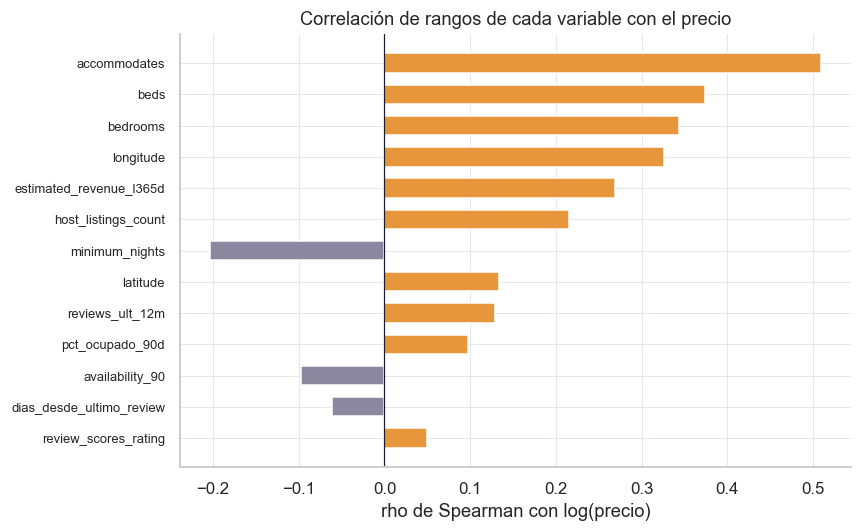

In [27]:
# Correlacion de cada variable candidata con el precio
orden_corr = corr.reindex(corr.abs().sort_values().index)                  # ordena de la más débil a la más fuerte
colores = [ACENTO if v >= 0 else GRIS for v in orden_corr]                 # un color según el signo

fig, ax = plt.subplots(figsize=(8, 5))                                     # una sola figura
ax.barh(orden_corr.index, orden_corr.values, color=colores, height=0.62)   # una barra por variable
ax.axvline(0, color=TINTA, linewidth=0.8)                                  # línea del cero
ax.set_title("Correlación de rangos de cada variable con el precio")       # título
ax.set_xlabel("rho de Spearman con log(precio)")                           # etiqueta del eje horizontal
ax.tick_params(axis="y", labelsize=8.5)                                    # nombres de variable más pequeños
plt.tight_layout()                                                         # acomoda la figura
plt.show()                                                                 # la muestra

### Conclusión: fugas

`estimated_revenue_l365d` es una fuga. El ingreso dividido entre las noches ocupadas reproduce
el precio, de modo que se calcula con él. Su correlación con el precio es moderada, pero eso no
cambia la decisión: contiene lo que se quiere predecir.

Las demás columnas candidatas no muestran correlaciones que hagan sospechar una fuga.

Las variables de actividad, que son la calificación, la disponibilidad, el porcentaje ocupado y
los comentarios, no son fugas, pero un propietario nuevo no las tiene. Los modelos se comparan
con ellas y sin ellas para decidir si el modelo final las usa.

## Paso 4: Columnas

Esta sección decide qué columnas entran al modelo, cuáles se crean y cuáles se descartan.

Cuatro de ellas no se pueden usar tal como vienen. `bathrooms_text` es texto con el número de
baños, `amenities` es una lista de comodidades en texto, `property_type` tiene muchas
categorías y `host_is_superhost` llega como las letras t y f.

In [28]:
print(train["bathrooms_text"].value_counts(dropna=False).head(15))         # los 15 textos de baños más frecuentes (dropna=False cuenta también los vacíos)
print()                                                                    # línea en blanco para separar
print("Ejemplo de amenities:", train["amenities"].iloc[0][:300])           # los primeros 300 caracteres de la lista de comodidades del primer alojamiento
print()                                                                    # línea en blanco
print("Tipos de propiedad distintos:", train["property_type"].nunique())   # cuántas categorías distintas hay de tipo de propiedad
print(train["property_type"].value_counts().head(10))                      # las 10 categorías más frecuentes
print()                                                                    # línea en blanco
print(train["host_is_superhost"].value_counts(dropna=False))               # cuántos superhost "t", "f" y vacíos hay

bathrooms_text
1 bath              7809
1 private bath      1973
2 baths             1874
1.5 baths            895
1 shared bath        857
2.5 baths            359
3 baths              259
2 shared baths       152
1.5 shared baths      98
3.5 baths             90
4 baths               67
0 shared baths        67
3 shared baths        46
0 baths               42
5 baths               30
Name: count, dtype: int64

Ejemplo de amenities: ["Shampoo", "Coffee maker", "Hair dryer", "Iron", "Room-darkening shades", "Clothing storage", "Wifi", "Body soap", "TV", "Breakfast", "Pets allowed", "Hangers", "Building staff", "Fire extinguisher", "Safe", "Air conditioning", "Heating", "Free parking on premises", "Elevator", "Dedicated workspace

Tipos de propiedad distintos: 65
property_type
Entire rental unit             8203
Private room in rental unit    1129
Private room in home           1057
Entire loft                     899
Entire serviced apartment       828
Room in hotel                   

### Crear las columnas nuevas

La clase `CrearColumnas` reúne estas transformaciones para que queden dentro del
preprocesamiento y se apliquen igual en entrenamiento y en prueba.

`n_banos` extrae el número de baños del texto, contando medio baño como 0,5 y la ausencia de
baño como cero. `bano_compartido` marca con 1 los baños compartidos, que presumiblemente bajan
el precio. `n_amenities` cuenta los elementos de la lista de comodidades. `es_superhost`
convierte las letras t y f en 1 y 0. `sin_reviews` marca los alojamientos que nunca recibieron
un comentario.

In [29]:
import json                                                                # json sirve para leer la lista de comodidades que viene como texto

def contar_amenities(texto):                                               # función: cuenta cuántas comodidades hay en el texto
    try:                                                                   # intenta leer el texto como lista
        return len(json.loads(texto))                                      # convierte el texto en lista y cuenta sus elementos
    except (TypeError, ValueError):                                        # si el texto está vacío o dañado
        return np.nan                                                      # devuelve vacío (se rellena después)

class CrearColumnas(BaseEstimator, TransformerMixin):                      # clase propia: sigue las reglas de sklearn para poder ir dentro del Pipeline
    def fit(self, X, y=None):                                              # fit: aquí no hay nada que aprender
        return self                                                        # devuelve el mismo objeto, como exige sklearn

    def transform(self, X):                                                # transform: aplica los cambios a la tabla
        X = X.copy()                                                       # trabaja sobre una copia para no modificar la tabla original
        texto = X["bathrooms_text"].str.lower()                            # pasa el texto de baños a minúsculas para compararlo fácil
        numero = texto.str.extract(r"(\d+(?:\.\d+)?)")[0].astype(float)    # extrae el primer número del texto (con decimales, como 1.5)
        numero = numero.mask(texto.str.contains("half", na=False) & numero.isna(), 0.5)   # si dice "half" y no tiene número, vale 0,5
        numero = numero.mask(texto.str.contains("no bathroom", na=False), 0.0)            # si dice "no bathroom", vale 0
        X["n_banos"] = numero                                              # guarda el número de baños como columna nueva
        X["bano_compartido"] = texto.str.contains("shared", na=False).astype(int)         # 1 si el texto dice "shared", 0 si no
        X["n_amenities"] = X["amenities"].apply(contar_amenities)          # cuenta las comodidades de cada alojamiento
        X["es_superhost"] = (X["host_is_superhost"] == "t").astype(int)    # 1 si es superhost ("t"), 0 si no
        X["sin_reviews"] = X["review_scores_rating"].isna().astype(int)    # 1 si nunca tuvo comentarios (no tiene calificación)
        return X                                                           # devuelve la tabla con las columnas nuevas

In [30]:
con_nuevas = CrearColumnas().fit_transform(train)                          # aplica la clase a entrenamiento y crea las columnas nuevas

print("Alojamientos con baño compartido:", con_nuevas["bano_compartido"].sum())   # cuántos tienen baño compartido (suma de los 1)
print()                                                                    # línea en blanco para separar
print("Precio mediano según baño compartido (0 = privado, 1 = compartido):")   # título
print(con_nuevas.groupby("bano_compartido")["price_num"].median())         # precio mediano de cada grupo
print()                                                                    # línea en blanco para separar
nuevas_cols = ["n_banos", "bano_compartido", "n_amenities", "es_superhost", "sin_reviews"]   # las 5 columnas que creamos
corr_nuevas = con_nuevas[nuevas_cols].corrwith(np.log1p(con_nuevas["price_num"]), method="spearman")   # correlación de cada una con el logaritmo del precio
print("Correlación de las columnas nuevas con log(precio):")               # título
print(corr_nuevas.round(3))                                                # imprime las correlaciones con 3 decimales


Alojamientos con baño compartido: 1371

Precio mediano según baño compartido (0 = privado, 1 = compartido):
bano_compartido
0   167,998.00
1    70,000.00
Name: price_num, dtype: float64

Correlación de las columnas nuevas con log(precio):
n_banos            0.32
bano_compartido   -0.34
n_amenities        0.33
es_superhost       0.13
sin_reviews       -0.12
dtype: float64


### Rellenar faltantes por grupo

La clase `RellenarPorGrupo` aplica lo que salió de comparar errores, que es rellenar `beds` y
`bedrooms` con la mediana según la capacidad. `n_banos` se suma a esa lista porque también
depende de cuánta gente cabe.

Las medianas se aprenden en `fit` con la partición de entrenamiento y se aplican en
`transform`, de modo que la de prueba no interviene en el relleno.

In [31]:
class RellenarPorGrupo(BaseEstimator, TransformerMixin):                   # clase propia que rellena vacíos con la mediana de cada grupo
    def __init__(self, columnas, grupo):                                   # al crearla se le dice qué columnas rellenar y por cuál agrupar
        self.columnas = columnas                                           # guarda la lista de columnas a rellenar
        self.grupo = grupo                                                 # guarda la columna que define los grupos

    def fit(self, X, y=None):                                              # fit: aprende las medianas (solo con los datos que reciba)
        self.medianas_ = {c: X.groupby(self.grupo)[c].median() for c in self.columnas}   # mediana de cada columna por grupo (el guion bajo final indica "aprendido")
        self.globales_ = {c: X[c].median() for c in self.columnas}         # mediana general de cada columna, por si aparece un grupo nuevo
        return self                                                        # devuelve el mismo objeto, como exige sklearn

    def transform(self, X):                                                # transform: rellena los vacíos usando lo aprendido
        X = X.copy()                                                       # trabaja sobre una copia
        for c in self.columnas:                                            # recorre cada columna a rellenar
            por_grupo = X[self.grupo].map(self.medianas_[c])               # a cada fila le asigna la mediana de su grupo
            X[c] = X[c].fillna(por_grupo).fillna(self.globales_[c])        # rellena con la del grupo y, si no hay, con la general
        return X                                                           # devuelve la tabla rellenada

### Preprocesamiento completo

Los pasos quedan encadenados en un solo objeto. Primero `CrearColumnas`, después
`RellenarPorGrupo`, y al final el tratamiento por tipo de columna. A las numéricas les rellena
con la mediana lo que quede vacío y las escala; a las categóricas las convierte en columnas de
0 y 1, agrupando en una categoría común las que pesan menos del uno por ciento.

Una función con un interruptor arma la versión sin las variables de actividad y la versión con
ellas, porque un propietario nuevo no dispone de esas variables.

In [32]:
CATEGORICAS = ["property_type", "room_type", "neighbourhood_cleansed"]    # columnas de texto que se convierten en 0/1
NUM_BASE = [                                                               # numéricas que cualquier dueño conoce desde el día uno
    "latitude", "longitude", "accommodates", "bedrooms", "beds",           # ubicación, capacidad, habitaciones y camas
    "n_banos", "bano_compartido", "n_amenities",                           # baños, baño compartido y número de comodidades (las creamos nosotros)
    "minimum_nights", "host_listings_count", "es_superhost",               # noches mínimas, alojamientos del dueño y superhost
]                                                                          # cierra la lista
NUM_ACTIVIDAD = [                                                          # numéricas de actividad: solo existen si el alojamiento ya operó
    "review_scores_rating", "availability_90", "pct_ocupado_90d",          # calificación, disponibilidad a 90 días y % ocupado
    "reviews_ult_12m", "dias_desde_ultimo_review", "sin_reviews",          # comentarios del último año, días desde el último y marca de "sin comentarios"
]                                                                          # cierra la lista

def armar_preprocesador(con_actividad):                                    # función: arma el preprocesamiento; con_actividad decide si incluye las 6 de actividad
    numericas = NUM_BASE + (NUM_ACTIVIDAD if con_actividad else [])        # lista de numéricas: las base, más las de actividad si se pidió
    transformador = ColumnTransformer([                                    # aplica un tratamiento distinto a cada grupo de columnas
        ("num", Pipeline([                                                 # para las numéricas, dos pasos seguidos:
            ("imputar", SimpleImputer(strategy="median")),                 # primero rellena vacíos con la mediana
            ("escalar", StandardScaler()),                                 # luego las escala (promedio 0, desviación 1)
        ]), numericas),                                                    # cierra el grupo y le dice a qué columnas aplica
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist",        # para las categóricas: convierte cada categoría en una columna de 0/1
                              min_frequency=0.01, sparse_output=False),    # las que pesan menos del 1% se agrupan en "otros"; sparse_output=False da una tabla normal
         CATEGORICAS),                                                     # le dice a qué columnas aplica
    ])                                                                     # cierra el ColumnTransformer
    return Pipeline([                                                      # encadena los tres pasos en el orden correcto
        ("crear", CrearColumnas()),                                        # 1) crea las columnas nuevas
        ("rellenar", RellenarPorGrupo(["beds", "bedrooms", "n_banos"], "accommodates")),   # 2) rellena camas, habitaciones y baños por capacidad
        ("columnas", transformador),                                       # 3) imputa, escala y codifica
    ])                                                                     # cierra el Pipeline

X_train = train.drop(columns=["price_num", "price"])                       # variables de entrenamiento: toda la tabla menos el precio (número y texto)
y_train = train["price_num"]                                               # lo que queremos predecir: el precio como número
X_test = test.drop(columns=["price_num", "price"])                         # variables de prueba, sin el precio
y_test = test["price_num"]                                                 # precio real de prueba (se usa solo al final)

### Tabla de columnas: qué entra, qué se crea y qué se descarta

La tabla de anuncios trae noventa columnas y el modelo usa pocas. La revisión las clasifica una
por una en cuatro grupos.

Entran tal cual las columnas originales que el modelo usa directamente. Entran como materia
prima las de texto de las que se extrae una columna nueva, y la fecha de la que salen los días
desde el último comentario. Se crean las columnas nuevas, algunas calculadas desde el
calendario y los comentarios. Se descartan las vacías, las fugas, los identificadores y
enlaces, y las que quedan fuera de la selección.

In [33]:
originales = [c for c in listings.columns if c != "price_num"]             # las 90 columnas originales del archivo (sin price_num, que agregamos nosotros)

tal_cual = [                                                               # originales que el modelo usa directamente
    "property_type", "room_type", "neighbourhood_cleansed",                # tipo de propiedad, tipo de habitación y barrio
    "latitude", "longitude", "accommodates", "bedrooms", "beds",           # ubicación y capacidad
    "minimum_nights", "host_listings_count",                               # noches mínimas y alojamientos del dueño
    "review_scores_rating", "availability_90",                             # calificación y disponibilidad a 90 días
]                                                                          # cierra la lista
materia_prima = ["bathrooms_text", "amenities", "host_is_superhost", "last_review"]   # textos y fecha de los que salen columnas nuevas
creadas = [                                                                # columnas que construimos nosotros
    "n_banos", "bano_compartido", "n_amenities", "es_superhost", "sin_reviews",   # salen de las columnas de texto de arriba
    "pct_ocupado_90d", "reviews_ult_12m", "dias_desde_ultimo_review",      # las tres primeras salen de calendar, reviews y last_review
]                                                                          # cierra la lista

etiqueta_fuga = ["price", "estimated_revenue_l365d"]                       # price es la etiqueta (texto) y estimated_revenue es la fuga que comprobamos
vacias = [c for c in originales if listings[c].isna().all() and c not in tal_cual + materia_prima]   # columnas totalmente vacías
ids_enlaces = [c for c in originales if (c in ["id", "scrape_id", "host_id", "host_profile_id"] or c.endswith("_url")) and c not in vacias]   # identificadores y enlaces
asignadas = set(tal_cual + materia_prima + etiqueta_fuga + vacias + ids_enlaces)   # todas las que ya tienen grupo
otras = [c for c in originales if c not in asignadas]                      # el resto: textos libres, datos del dueño, comentarios, etc.

resumen_cols = pd.DataFrame({                                              # arma la tabla resumen
    "Grupo": ["Entran tal cual", "Entran como materia prima", "Se crean",  # nombre de cada grupo
              "Descartadas: etiqueta y fuga", "Descartadas: vacías",
              "Descartadas: identificadores y enlaces", "Descartadas: otras"],
    "Cantidad": [len(tal_cual), len(materia_prima), len(creadas),          # cuántas columnas tiene cada grupo
                 len(etiqueta_fuga), len(vacias), len(ids_enlaces), len(otras)],
    "Columnas": [tal_cual, materia_prima, creadas,                         # cuáles son
                 etiqueta_fuga, vacias, ids_enlaces, otras],
})                                                                         # cierra la tabla
with pd.option_context("display.max_colwidth", None):                      # permite ver las listas completas sin cortarlas con "..."
    display(resumen_cols)                                                  # muestra la tabla

total_modelo = len(NUM_BASE) + len(NUM_ACTIVIDAD) + len(CATEGORICAS)       # cuántas variables usa el modelo en total
print("Columnas originales:", len(originales))                             # cuántas tenía listings
print("Revisadas en la tabla:", len(tal_cual) + len(materia_prima) + len(etiqueta_fuga) + len(vacias) + len(ids_enlaces) + len(otras))   # debe dar lo mismo que las originales
print("Variables que usa el modelo:", total_modelo)                        # las variables finales del modelo (con actividad)

,Grupo,Cantidad,Columnas
0,Entran tal cual,12,"[property_type, room_type, neighbourhood_cleansed, latitude, longitude, accommodates, bedrooms, beds, minimum_nights, host_listings_count, review_scores_rating, availability_90]"
1,Entran como materia prima,4,"[bathrooms_text, amenities, host_is_superhost, last_review]"
2,Se crean,8,"[n_banos, bano_compartido, n_amenities, es_superhost, sin_reviews, pct_ocupado_90d, reviews_ult_12m, dias_desde_ultimo_review]"
3,Descartadas: etiqueta y fuga,2,"[price, estimated_revenue_l365d]"
4,Descartadas: vacías,14,"[neighborhood_overview, host_since, host_response_time, host_response_rate, host_acceptance_rate, host_thumbnail_url, host_neighbourhood, host_total_listings_count, host_verifications, neighbourhood, neighbourhood_group_cleansed, bathrooms, calendar_updated, instant_bookable]"
5,Descartadas: identificadores y enlaces,9,"[id, listing_url, scrape_id, picture_url, host_id, host_url, host_profile_id, host_profile_url, host_picture_url]"
6,Descartadas: otras,49,"[last_scraped, source, name, description, host_name, hosts_time_as_user_years, hosts_time_as_user_months, hosts_time_as_host_years, hosts_time_as_host_months, host_location, host_about, host_has_profile_pic, host_identity_verified, price_quote_checkin_date, price_quote_checkout_date, price_quote_total_price, price_quote_price_per_night, price_quote_raw, maximum_nights, minimum_minimum_nights, maximum_minimum_nights, minimum_maximum_nights, maximum_maximum_nights, minimum_nights_avg_ntm, maximum_nights_avg_ntm, has_availability, availability_30, availability_60, availability_365, calendar_last_scraped, number_of_reviews, number_of_reviews_ltm, number_of_reviews_l30d, availability_eoy, number_of_reviews_ly, estimated_occupancy_l365d, first_review, review_scores_accuracy, review_scores_cleanliness, review_scores_checkin, review_scores_communication, review_scores_location, review_scores_value, license, calculated_host_listings_count, calculated_host_listings_count_entire_homes, calculated_host_listings_count_private_rooms, calculated_host_listings_count_shared_rooms, reviews_per_month]"


Columnas originales: 90
Revisadas en la tabla: 90
Variables que usa el modelo: 20


In [34]:
cotizacion = train["price_quote_price_per_night"]                          # la columna sospechosa, solo en entrenamiento
iguales = np.isclose(cotizacion, train["price_num"], rtol=0.001).mean() * 100   # % de alojamientos donde coincide con el precio (tolerancia de 0,1%)
corr = cotizacion.corr(train["price_num"], method="spearman")              # correlación de rangos (Spearman) con el precio
print(f"Coincide con el precio en el {iguales:.1f}% de los casos")         # imprime el porcentaje de coincidencia
print(f"Correlación con el precio: {corr:.3f}")                            # imprime la correlación (1 = idéntica)

Coincide con el precio en el 100.0% de los casos
Correlación con el precio: 1.000


### Conclusión: columnas

El modelo usa una fracción pequeña de las noventa columnas originales, repartida entre las que
entran directamente, las que provienen de las otras dos tablas y las que se construyen desde
columnas de texto. El resto se descarta por estar vacío, por ser identificador o enlace, o por
quedar fuera de la selección.

La revisión encontró una segunda fuga además del ingreso estimado. `price_quote_price_per_night`
es el mismo precio que se quiere predecir, y `price_quote_total_price` y `price_quote_raw`
también lo contienen. Con cualquiera de ellas el modelo parecería perfecto sin haber aprendido
nada.

## Paso 5: Modelos

Todos los modelos se comparan con la misma validación cruzada de cinco partes, con la misma
semilla y con el preprocesamiento dentro del mismo objeto, de modo que la comparación sea
justa. Se miden cuatro métricas, que son el error absoluto medio, la raíz del error cuadrático
medio, el R² y el error cuadrático en escala logarítmica.

La comparación arranca por los dos puntos de partida. La línea base predice siempre la mediana
de la ciudad, y la regla a mano la mediana de cada barrio, ahora medida con esta misma
validación. Un modelo sencillo con y sin logaritmo del precio justifica la transformación.

In [35]:
from sklearn.base import RegressorMixin                                    # clase base para que mi regla a mano se comporte como un modelo de regresión
from sklearn.dummy import DummyRegressor                                   # modelo "tonto" que sirve de línea base

cv = KFold(n_splits=5, shuffle=True, random_state=42)                      # validación cruzada: 5 partes, mezclando los datos, con semilla fija
metricas_cv = {                                                            # las 4 métricas que se calculan en cada parte
    "mae": "neg_mean_absolute_error",                                      # MAE (sklearn lo da en negativo, luego le cambio el signo)
    "rmse": "neg_root_mean_squared_error",                                 # RMSE
    "r2": "r2",                                                            # R²
    "rmsle": "neg_root_mean_squared_log_error",                            # RMSLE
}                                                                          # cierra el diccionario

class ReglaPorBarrio(BaseEstimator, RegressorMixin):                       # la regla a mano convertida en "modelo", para medirla con la misma validación
    def fit(self, X, y):                                                   # aprende: la mediana de precio de cada barrio
        self.medianas_ = y.groupby(X["neighbourhood_cleansed"]).median()   # mediana de precio por barrio
        self.global_ = y.median()                                          # mediana de toda la ciudad, por si aparece un barrio nuevo
        return self                                                        # devuelve el mismo objeto, como exige sklearn
    def predict(self, X):                                                  # predice: a cada alojamiento le asigna la mediana de su barrio
        return X["neighbourhood_cleansed"].map(self.medianas_).fillna(self.global_).to_numpy()   # mediana del barrio, o la global si no existe

def pipe(modelo, con_actividad, log=True):                                 # función: arma el Pipeline completo de un modelo
    base = Pipeline([("prep", armar_preprocesador(con_actividad)), ("modelo", modelo)])   # preprocesamiento seguido del modelo
    if log:                                                                # si se pidió usar logaritmo del precio
        return TransformedTargetRegressor(regressor=base, func=np.log1p, inverse_func=np.expm1)   # entrena con el log del precio y devuelve las predicciones en pesos
    return base                                                            # si no, devuelve el Pipeline normal

def evaluar(nombre, estimador):                                            # función: mide un modelo con la validación cruzada
    r = cross_validate(estimador, X_train, y_train, cv=cv, scoring=metricas_cv)   # entrena y evalúa en las 5 partes
    return {"Modelo": nombre, "MAE": -r["test_mae"].mean(), "RMSE": -r["test_rmse"].mean(),   # promedio de las 5 partes (con el signo corregido)
            "R2": r["test_r2"].mean(), "RMSLE": -r["test_rmsle"].mean(),   # R² y RMSLE promedio
            "Tiempo (s)": r["fit_time"].mean()}                            # segundos promedio que tardó en entrenar cada parte

In [36]:
modelos_rapidos = {                                                        # diccionario con los modelos a comparar (nombre: modelo)
    "Regresión lineal": LinearRegression(),                                # familia lineal: la más simple
    "Ridge": Ridge(),                                                      # lineal con penalización para no sobreajustar
    "KNN (15 vecinos)": KNeighborsRegressor(n_neighbors=15),               # predice con el promedio de los 15 alojamientos más parecidos
    "Árbol (profundidad 8)": DecisionTreeRegressor(max_depth=8, random_state=42),   # un árbol de decisión, limitado a 8 niveles para que no memorice
    "Random forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=42, n_jobs=-1),   # 200 árboles que votan (usa todos los núcleos del computador)
    "Gradient boosting": GradientBoostingRegressor(random_state=42),       # árboles en cadena, cada uno corrige al anterior
    "XGBoost": XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=5, random_state=42, n_jobs=-1),   # boosting optimizado
}                                                                          # cierra el diccionario

filas_sin = [                                                              # lista de resultados sin variables de actividad
    evaluar("Línea base (mediana de la ciudad)", DummyRegressor(strategy="median")),   # punto de partida 1
    evaluar("Regla a mano (mediana por barrio)", ReglaPorBarrio()),        # punto de partida 2
]                                                                          # cierra la lista

for nombre, modelo in modelos_rapidos.items():                             # recorre cada modelo del diccionario
    filas_sin.append(evaluar(nombre, pipe(modelo, con_actividad=False)))   # lo mide con el mismo Pipeline y la misma validación
    print(nombre, "listo")                                                 # avisa cuando termina cada uno

resultados_sin = pd.DataFrame(filas_sin).set_index("Modelo")               # junta todo en una tabla
display(resultados_sin.sort_values("MAE").map(lambda x: f"{x:,.3f}"))      # la muestra ordenada de menor a mayor MAE, con 3 decimales

Regresión lineal listo
Ridge listo


  File "c:\Users\USUARIO\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\USUARIO\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\USUARIO\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\USUARIO\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


KNN (15 vecinos) listo
Árbol (profundidad 8) listo
Random forest listo
Gradient boosting listo
XGBoost listo


,MAE,RMSE,R2,RMSLE,Tiempo (s)
Modelo,,,,,
Random forest,"54,961.147","144,267.090",0.465,0.358,1.096
XGBoost,"57,919.079","145,924.412",0.453,0.370,0.441
Gradient boosting,"62,066.424","154,107.660",0.390,0.394,2.647
KNN (15 vecinos),"63,644.869","156,450.499",0.371,0.409,0.178
Árbol (profundidad 8),"66,517.610","161,728.686",0.324,0.420,0.206
Regresión lineal,"71,710.623","166,085.614",0.291,0.450,0.235
Ridge,"71,711.191","166,093.872",0.291,0.450,0.150
Regla a mano (mediana por barrio),"92,295.686","196,875.505",0.004,0.613,0.010
Línea base (mediana de la ciudad),"96,997.815","201,584.186",-0.045,0.654,0.009


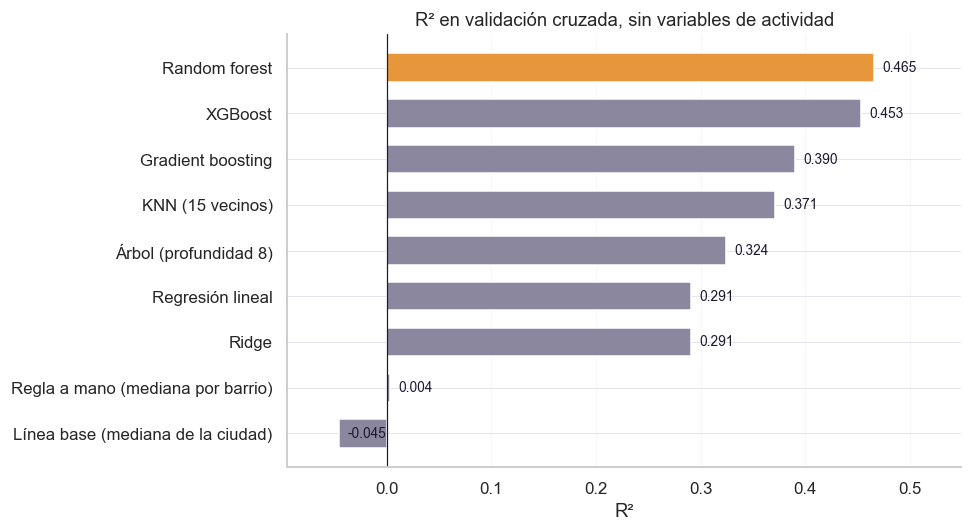

In [37]:
TINTA, ACENTO, GRIS = "#1B1A2F", "#E8963C", "#8A879E"                      # colores del proyecto

orden = resultados_sin.sort_values("R2")                                   # ordena los modelos de menor a mayor R², leyendo la tabla de resultados
mejor = resultados_sin["R2"].idxmax()                                      # nombre del modelo con mayor R²
colores = [ACENTO if nombre == mejor else GRIS for nombre in orden.index]  # destaca el mejor y deja los demás en gris

fig, ax = plt.subplots(figsize=(9, 5))                                     # una sola figura
ax.barh(orden.index, orden["R2"], color=colores, height=0.62)              # una barra por modelo
for i, valor in enumerate(orden["R2"]):                                    # escribe el valor junto a cada barra
    ax.text(valor + 0.008, i, f"{valor:.3f}", va="center", fontsize=9, color=TINTA)
ax.axvline(0, color=TINTA, linewidth=0.8)                                  # línea del cero
ax.set_xlim(min(0, orden["R2"].min()) - 0.05, orden["R2"].max() * 1.18)    # deja espacio para las etiquetas
ax.set_title("R² en validación cruzada, sin variables de actividad")       # título
ax.set_xlabel("R²")                                                        # etiqueta del eje horizontal
ax.grid(axis="x", alpha=0.3)                                               # cuadrícula tenue
plt.tight_layout()                                                         # acomoda la figura
plt.show()                                                                 # la muestra


In [38]:
modelos_lentos = {                                                         # los dos modelos que tardan más
    "SVR": SVR(),                                                          # máquina de soporte vectorial con sus valores por defecto
    "Red neuronal (64-32)": MLPRegressor(hidden_layer_sizes=(64, 32),      # red con dos capas ocultas, de 64 y 32 neuronas
                                         early_stopping=True,              # se detiene sola si deja de mejorar
                                         max_iter=300, random_state=42),   # máximo 300 vueltas, semilla fija
}                                                                          # cierra el diccionario

filas_lentos = []                                                          # lista de resultados de estos dos modelos (se vacía cada vez que corre la celda)
for nombre, modelo in modelos_lentos.items():                              # recorre cada modelo
    filas_lentos.append(evaluar(nombre, pipe(modelo, con_actividad=False)))   # lo mide con el mismo Pipeline y la misma validación
    print(nombre, "listo")                                                 # avisa cuando termina cada uno

resultados_sin = pd.DataFrame(filas_sin + filas_lentos).set_index("Modelo")   # junta los rápidos y los lentos en una sola tabla
display(resultados_sin.sort_values("MAE").map(lambda x: f"{x:,.3f}"))      # la muestra ordenada por MAE, con 3 decimales

SVR listo
Red neuronal (64-32) listo


,MAE,RMSE,R2,RMSLE,Tiempo (s)
Modelo,,,,,
Random forest,"54,961.147","144,267.090",0.465,0.358,1.096
XGBoost,"57,919.079","145,924.412",0.453,0.370,0.441
SVR,"60,343.483","156,674.123",0.371,0.392,6.219
Gradient boosting,"62,066.424","154,107.660",0.390,0.394,2.647
KNN (15 vecinos),"63,644.869","156,450.499",0.371,0.409,0.178
Árbol (profundidad 8),"66,517.610","161,728.686",0.324,0.420,0.206
Red neuronal (64-32),"66,530.209","223,300.772",-0.550,0.415,3.716
Regresión lineal,"71,710.623","166,085.614",0.291,0.450,0.235
Ridge,"71,711.191","166,093.872",0.291,0.450,0.150


### ¿Aportan las variables de actividad?

La comparación repite los mismos modelos añadiendo las seis variables de actividad, que son la
calificación, la disponibilidad a noventa días, el porcentaje ocupado, los comentarios del
último año, los días desde el último comentario y la marca de ausencia de comentarios.

Un propietario nuevo no dispone de ninguna de ellas, de modo que la diferencia de error decide
si el modelo final las usa.

In [39]:
todos = {**modelos_rapidos, **modelos_lentos}                              # junta los dos diccionarios de modelos en uno solo (los 9 modelos)

filas_con = [                                                              # lista de resultados CON variables de actividad
    evaluar("Línea base (mediana de la ciudad)", DummyRegressor(strategy="median")),   # punto de partida 1 (no usa variables, da igual)
    evaluar("Regla a mano (mediana por barrio)", ReglaPorBarrio()),        # punto de partida 2 (tampoco usa actividad)
]                                                                          # cierra la lista

for nombre, modelo in todos.items():                                       # recorre los 9 modelos
    filas_con.append(evaluar(nombre, pipe(modelo, con_actividad=True)))    # los mide con las variables de actividad incluidas
    print(nombre, "listo")                                                 # avisa cuando termina cada uno

resultados_con = pd.DataFrame(filas_con).set_index("Modelo")               # junta todo en una tabla
comparacion = pd.DataFrame({                                               # tabla que pone lado a lado los resultados sin y con actividad
    "MAE sin actividad": resultados_sin["MAE"],                            # error típico sin las variables de actividad
    "MAE con actividad": resultados_con["MAE"],                            # error típico con ellas
    "RMSLE sin actividad": resultados_sin["RMSLE"],                        # error relativo sin ellas
    "RMSLE con actividad": resultados_con["RMSLE"],                        # error relativo con ellas
}).sort_values("MAE con actividad")                                        # ordenada de menor a mayor MAE con actividad
display(comparacion.map(lambda x: f"{x:,.3f}"))                            # la muestra con 3 decimales

Regresión lineal listo
Ridge listo
KNN (15 vecinos) listo
Árbol (profundidad 8) listo
Random forest listo
Gradient boosting listo
XGBoost listo
SVR listo
Red neuronal (64-32) listo


,MAE sin actividad,MAE con actividad,RMSLE sin actividad,RMSLE con actividad
Modelo,,,,
Random forest,"54,961.147","55,203.712",0.358,0.356
XGBoost,"57,919.079","56,657.474",0.370,0.359
SVR,"60,343.483","59,209.523",0.392,0.383
Gradient boosting,"62,066.424","60,669.867",0.394,0.384
KNN (15 vecinos),"63,644.869","65,682.294",0.409,0.421
Red neuronal (64-32),"66,530.209","66,276.078",0.415,0.412
Árbol (profundidad 8),"66,517.610","67,775.772",0.420,0.426
Regresión lineal,"71,710.623","70,565.887",0.450,0.442
Ridge,"71,711.191","70,566.332",0.450,0.442


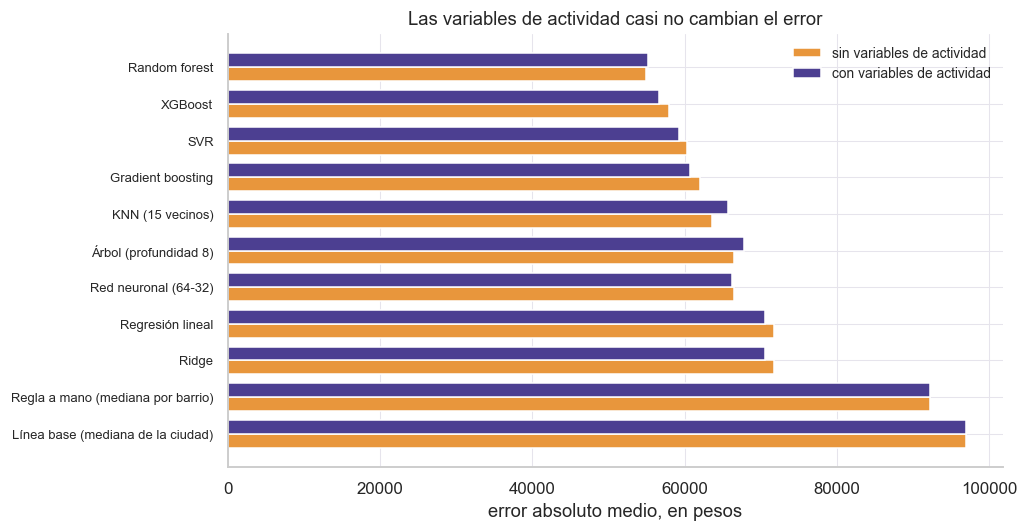

In [40]:
# Error con y sin las variables de actividad
orden_act = comparacion.sort_values("MAE sin actividad", ascending=False)   # ordena de mayor a menor error
posicion = np.arange(len(orden_act))                                       # una posición por modelo
alto = 0.38                                                               # alto de cada barra

fig, ax = plt.subplots(figsize=(9.5, 5))                                   # una sola figura
ax.barh(posicion - alto / 2, orden_act["MAE sin actividad"], height=alto,  # error sin las variables de actividad
        color=ACENTO, label="sin variables de actividad")
ax.barh(posicion + alto / 2, orden_act["MAE con actividad"], height=alto,  # error con ellas
        color=MORADO, label="con variables de actividad")
ax.set_yticks(posicion)                                                    # una marca por modelo
ax.set_yticklabels(orden_act.index, fontsize=8.5)                          # con su nombre
ax.set_xlabel("error absoluto medio, en pesos")                            # etiqueta del eje horizontal
ax.set_title("Las variables de actividad casi no cambian el error")        # título
ax.legend(fontsize=9)                                                      # leyenda, porque hay dos series
plt.tight_layout()                                                         # acomoda la figura
plt.show()                                                                 # la muestra

### Conclusión: modelos

Los modelos cubren cinco familias, que son los lineales, los vecinos más cercanos, los árboles,
los ensambles y las máquinas de soporte vectorial con la red neuronal, además de la línea base y
la regla a mano.

Los ensambles de árboles superan a los lineales, porque el precio depende de combinaciones de
atributos, como el tamaño junto con la ubicación, que un modelo aditivo no representa.

Entrenar sobre el logaritmo del precio reduce el error y evita las predicciones negativas.

Las variables de actividad casi no ayudan, y el mejor modelo incluso empeora ligeramente al
incluirlas, de modo que el modelo final prescinde de ellas y sirve también a un propietario
nuevo.

La red neuronal obtiene un R² negativo porque unos pocos casos se disparan al devolver el
precio a pesos, y queda descartada sin afinar.

## Paso 6: Evaluación

La elección se hace entre los dos mejores. Antes de decidir, la comparación revisa si el que
lidera gana en cada una de las cinco partes de la validación o solo en el promedio.

El modelo elegido se evalúa una sola vez contra la partición de prueba, que no se había tocado,
y se compara con la regla a mano.

In [41]:
por_parte = {}                                                             # diccionario donde guardo el MAE de cada parte, por modelo
for nombre in ["Random forest", "XGBoost"]:                                # los dos finalistas
    r = cross_validate(pipe(todos[nombre], con_actividad=False), X_train, y_train, cv=cv, scoring=metricas_cv)   # los mide de nuevo con la misma validación
    por_parte[nombre] = -r["test_mae"]                                     # guarda el MAE de cada una de las 5 partes (con el signo corregido)
    maes = por_parte[nombre]                                               # atajo para escribir menos
    print(f"{nombre}: MAE por parte {[int(round(m)) for m in maes]} | promedio {maes.mean():,.0f} | desviación {maes.std():,.0f}")   # muestra los 5 errores, el promedio y qué tanto varían

gana_rf = (por_parte["Random forest"] < por_parte["XGBoost"]).sum()        # en cuántas partes el Random forest tuvo menor error
print(f"El Random forest tiene menor MAE en {gana_rf} de 5 partes")        # imprime el conteo

Random forest: MAE por parte [55135, 53070, 57606, 53096, 55899] | promedio 54,961 | desviación 1,730
XGBoost: MAE por parte [58288, 56418, 60778, 55385, 58726] | promedio 57,919 | desviación 1,878
El Random forest tiene menor MAE en 5 de 5 partes


### Modelo elegido: Random forest

El Random forest obtiene menor error que XGBoost en las cuatro métricas y gana en las cinco
partes de la validación, con una diferencia mayor que la variación entre partes. Además entrena
en poco más de un segundo y no exige afinar parámetros.

La elección es el Random forest sin las variables de actividad, para que el modelo sirva
también a un propietario que todavía no publicó.

In [42]:
modelo_final = pipe(todos["Random forest"], con_actividad=False)           # arma el Pipeline del modelo elegido, sin variables de actividad
modelo_final.fit(X_train, y_train)                                         # lo entrena con TODO el conjunto de entrenamiento
pred_rf = modelo_final.predict(X_test)                                     # predice el precio de los alojamientos de prueba

regla = ReglaPorBarrio().fit(X_train, y_train)                             # entrena la regla a mano (mediana por barrio) con el mismo entrenamiento
linea_base = DummyRegressor(strategy="median").fit(X_train, y_train)       # entrena la línea base (mediana de la ciudad)

final = pd.DataFrame({                                                     # tabla con los resultados sobre la prueba
    "Línea base": metricas(y_test, linea_base.predict(X_test)),            # métricas de la línea base en la prueba
    "Regla a mano": metricas(y_test, regla.predict(X_test)),               # métricas de la regla a mano en la prueba
    "Random forest (prueba)": metricas(y_test, pred_rf),                   # métricas del modelo elegido en la prueba
}).T                                                                       # .T gira la tabla: cada modelo queda en una fila
final.loc["Random forest (validación cruzada)"] = resultados_sin.loc["Random forest", ["MAE", "RMSE", "R2", "RMSLE"]]   # agrega, para comparar, lo que dio en la validación cruzada
display(final.map(lambda x: f"{x:,.3f}"))                                  # muestra la tabla con 3 decimales

mejora = (1 - final.loc["Random forest (prueba)", "MAE"] / final.loc["Regla a mano", "MAE"]) * 100   # cuánto bajó el error frente a la regla a mano, en porcentaje
print(f"El Random forest reduce el MAE un {mejora:.1f}% frente a la regla a mano")   # imprime ese porcentaje

,MAE,RMSE,R2,RMSLE
Línea base,"97,773.345","207,299.584",-0.043,0.661
Regla a mano,"92,943.425","202,498.887",0.005,0.621
Random forest (prueba),"55,218.048","143,401.019",0.501,0.365
Random forest (validación cruzada),"54,961.147","144,267.090",0.465,0.358


El Random forest reduce el MAE un 40.6% frente a la regla a mano


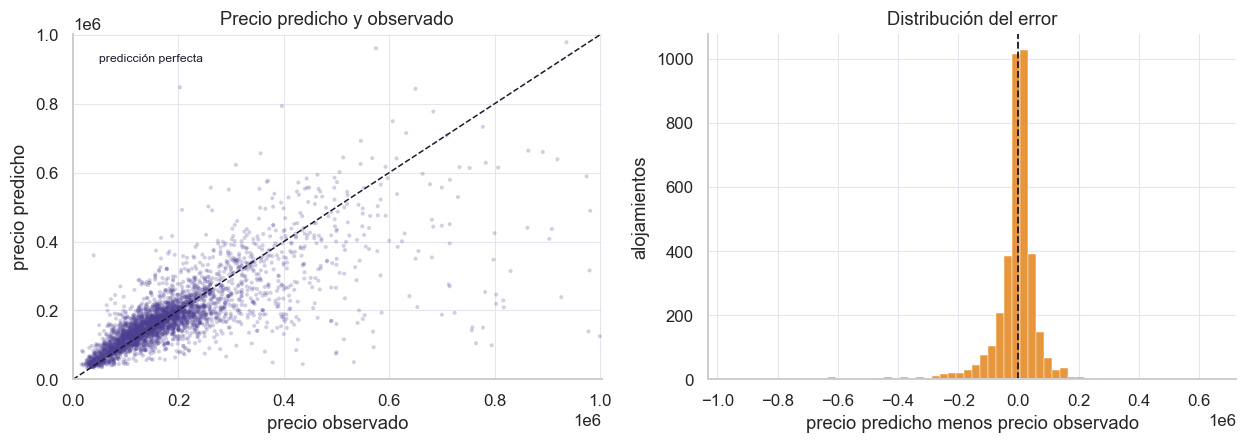

In [43]:
# Precio predicho frente al observado, en la particion de prueba
fig, ejes = plt.subplots(1, 2, figsize=(11.5, 4.2))                        # dos paneles

limite = float(np.percentile(y_test, 99))                                  # recorta la cola para que la nube sea legible
ejes[0].scatter(y_test, pred_rf, s=7, alpha=0.25, color=MORADO, edgecolors="none")   # cada punto es un alojamiento
ejes[0].plot([0, limite], [0, limite], color=TINTA, linewidth=1, linestyle="--")     # línea de predicción perfecta
ejes[0].set_xlim(0, limite); ejes[0].set_ylim(0, limite)                   # mismos límites en los dos ejes
ejes[0].set_title("Precio predicho y observado")                           # título del panel
ejes[0].set_xlabel("precio observado"); ejes[0].set_ylabel("precio predicho")
ejes[0].text(limite * 0.05, limite * 0.92, "predicción perfecta", fontsize=8, color=TINTA)

residuo = pred_rf - y_test.to_numpy()                                      # diferencia entre lo predicho y lo observado
ejes[1].hist(residuo[np.abs(residuo) < limite], bins=60, color=ACENTO,     # distribución del error
             edgecolor="white", linewidth=0.3)
ejes[1].axvline(0, color=TINTA, linewidth=1.2, linestyle="--")             # línea del cero
ejes[1].set_title("Distribución del error")                                # título del panel
ejes[1].set_xlabel("precio predicho menos precio observado"); ejes[1].set_ylabel("alojamientos")

plt.tight_layout()                                                         # acomoda los paneles
plt.show()                                                                 # los muestra

In [44]:
prep_final = modelo_final.regressor_.named_steps["prep"]                   # saca el preprocesamiento ya entrenado dentro del modelo final
nombres = prep_final.named_steps["columnas"].get_feature_names_out()       # nombres de las columnas que recibió el Random forest (ya con las categorías abiertas en 0/1)
importancias = pd.Series(modelo_final.regressor_.named_steps["modelo"].feature_importances_, index=nombres)   # cuánto pesa cada columna en las decisiones del bosque

def variable_original(nombre):                                             # función: devuelve de qué variable original viene cada columna
    nombre = nombre.split("__", 1)[1]                                      # quita el prefijo "num__" o "cat__"
    for c in CATEGORICAS:                                                  # revisa cada variable categórica
        if nombre.startswith(c):                                           # si la columna empieza con su nombre
            return c                                                       # la agrupa bajo esa variable
    return nombre                                                          # si es numérica, devuelve su propio nombre

por_variable = importancias.groupby(variable_original).sum().sort_values(ascending=False)   # suma el peso de todas las columnas de cada variable original
display(por_variable.head(12).map(lambda x: f"{x * 100:,.1f}%"))           # muestra las 12 más importantes, en porcentaje

room_type                 26.9%
n_banos                   16.0%
longitude                 12.9%
minimum_nights            11.2%
latitude                   8.7%
accommodates               5.4%
host_listings_count        5.2%
n_amenities                5.2%
property_type              2.8%
neighbourhood_cleansed     1.8%
bedrooms                   1.4%
beds                       1.3%
dtype: object

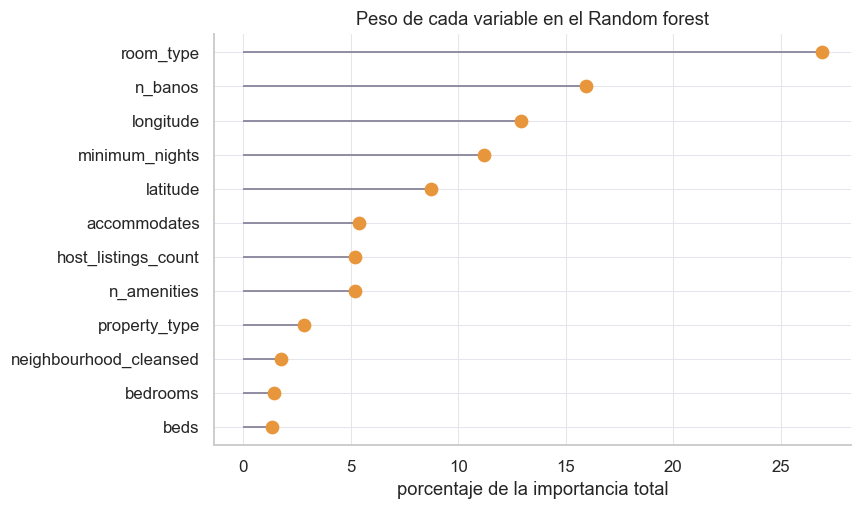

In [45]:
# Peso de cada variable en el modelo elegido
top_importancia = por_variable.head(12).iloc[::-1]                         # las 12 más importantes, de abajo hacia arriba

fig, ax = plt.subplots(figsize=(8, 4.8))                                   # una sola figura
ax.hlines(top_importancia.index, 0, top_importancia.values * 100, color=GRIS, linewidth=1.2)   # tallo de cada punto
ax.plot(top_importancia.values * 100, top_importancia.index, "o", color=ACENTO, markersize=8)  # punto de cada variable
ax.set_title("Peso de cada variable en el Random forest")                  # título
ax.set_xlabel("porcentaje de la importancia total")                        # etiqueta del eje horizontal
plt.tight_layout()                                                         # acomoda la figura
plt.show()                                                                 # la muestra

In [46]:
errores = pd.DataFrame({                                                   # tabla con el precio real, el predicho y el tipo de habitación
    "real": y_test, "predicho": pred_rf, "room_type": X_test["room_type"]  # precio real de prueba, predicción del modelo y tipo de habitación
})                                                                         # cierra la tabla
errores["error_abs"] = (errores["real"] - errores["predicho"]).abs()       # error absoluto de cada alojamiento, en pesos
resumen_error = errores.groupby("room_type").agg(                          # resume por tipo de habitación
    alojamientos=("real", "size"),                                         # cuántos hay
    precio_mediano=("real", "median"),                                     # su precio mediano real
    MAE=("error_abs", "mean"),                                             # su error promedio
)                                                                          # cierra el resumen
resumen_error["error_relativo_%"] = resumen_error["MAE"] / resumen_error["precio_mediano"] * 100   # error como porcentaje del precio típico
display(resumen_error.sort_values("alojamientos", ascending=False).map(lambda x: f"{x:,.1f}"))   # la muestra de mayor a menor cantidad, con 1 decimal

,alojamientos,precio_mediano,MAE,error_relativo_%
room_type,,,,
Entire home/apt,"2,697.0","180,906.1","62,599.0",34.6
Private room,"1,009.0","91,780.0","36,455.3",39.7
Shared room,25.0,"40,000.0","20,720.1",51.8
Hotel room,5.0,"199,000.0","32,764.1",16.5


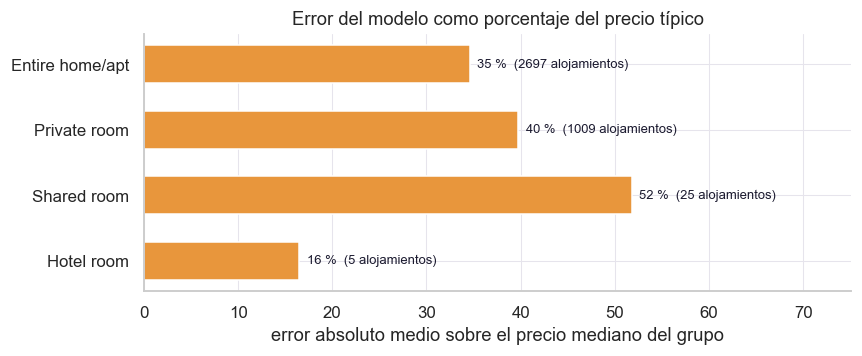

In [47]:
# Error relativo segun el tipo de habitacion
orden_tipo = resumen_error.sort_values("alojamientos", ascending=True)     # ordena de menos a más alojamientos

fig, ax = plt.subplots(figsize=(8, 3.4))                                   # una sola figura
barras = ax.barh(orden_tipo.index, orden_tipo["error_relativo_%"], color=ACENTO, height=0.58)   # una barra por tipo
for barra, (etiqueta, fila) in zip(barras, orden_tipo.iterrows()):         # escribe el detalle junto a cada barra
    ax.text(fila["error_relativo_%"] + 0.8, barra.get_y() + barra.get_height() / 2,
            f"{fila['error_relativo_%']:.0f} %  ({int(fila['alojamientos'])} alojamientos)",
            va="center", fontsize=8.5, color=TINTA)
ax.set_xlim(0, orden_tipo["error_relativo_%"].max() * 1.45)                # deja espacio para las etiquetas
ax.set_title("Error del modelo como porcentaje del precio típico")         # título
ax.set_xlabel("error absoluto medio sobre el precio mediano del grupo")    # etiqueta del eje horizontal
plt.tight_layout()                                                         # acomoda la figura
plt.show()                                                                 # la muestra

In [48]:
muestra = X_test.sample(5, random_state=42)                                # elige 5 alojamientos de prueba al azar (semilla fija para que salgan siempre los mismos)
ejemplos = pd.DataFrame({                                                  # tabla para comparar
    "tipo de habitación": muestra["room_type"],                            # tipo de habitación
    "huéspedes": muestra["accommodates"],                                  # cuántos huéspedes caben
    "barrio": muestra["neighbourhood_cleansed"],                           # barrio
    "precio real": y_test.loc[muestra.index],                              # precio real de cada uno
    "precio predicho": modelo_final.predict(muestra),                      # lo que predice el modelo para cada uno
})                                                                         # cierra la tabla
ejemplos["error"] = ejemplos["precio predicho"] - ejemplos["precio real"]  # cuánto se equivocó (positivo = cobraría de más)
display(ejemplos.round(0).map(lambda x: f"{x:,.0f}" if isinstance(x, (int, float)) else x))   # la muestra con números sin decimales

,tipo de habitación,huéspedes,barrio,precio real,precio predicho,error
5123,Entire home/apt,2,Chapinero,"230,500","266,092","35,592"
11858,Private room,2,Suba,"81,500","83,690","2,190"
15390,Private room,1,Fontibon,"80,000","81,588","1,588"
10068,Entire home/apt,4,Suba,"189,000","213,374","24,374"
15347,Entire home/apt,4,Usaquen,"712,982","275,616","-437,367"


### Conclusión: pregunta 1, ¿cuánto cobrar por noche?

El Random forest entrenado sobre el logaritmo del precio y sin variables de actividad predice
el precio por noche en la partición de prueba con un error bastante menor que el de la regla a
mano de la mediana por barrio. El resultado en prueba coincide con el de la validación cruzada,
de modo que el modelo no se sobreajustó.

Lo que más pesa es el tipo de habitación, el número de baños extraído del texto, la ubicación y
las noches mínimas. Como el modelo prescinde de calificaciones y comentarios, también sirve a
un propietario nuevo.

El límite es que el error sigue siendo una fracción apreciable del precio típico. El precio
depende de atributos que los datos no registran, como las fotografías, la decoración y el
estado del inmueble.